# Community Detection in Zachary's Karate Club Using Modularity
### DSC212  Project Report

**Student name**  `THARUN N S` 
**Roll number**  `IMS25220` 

## 1.Aim

In a network, a *community* is a group of nodes whose mutual ties are denser than what a random network with the same degree sequence would produce. This report hunts for such groups inside Zachary's Karate Club graph with the *modularity matrix* and a spectral cutting rule. The notebook proceeds as follows:
1. Construct the modularity matrix \(B\) for the complete graph (iteration 0) and verify its properties.

2. Divide each community using the signs of the leading eigenvector of its block matrix. Repeat for the resulting communities until the leading eigenvalue is non-positive or no valid split is possible.

3. Visualize the network after every accepted split, using a different colour for each community.

4. Calculate **degree centrality, betweenness centrality, closeness centrality, and clustering coefficient** for all 34 nodes at every iteration. For each metric, present its evolution using:
   - A complete 34-node table
   - A summary of changes between iterations
   - Line plots and a heat map
   - Network visualizations with node sizes based on the metric

5. Present one **complete table** comparing all 34 nodes across every iteration, from the original graph to their final communities.

6. Compare the final detected communities with the actual division of the Karate Club.

7. Repeat the analysis using **Newman's correction** to the block matrix. Study the changes in all four centrality measures using tables and visualizations.

8. Discuss the results, highlighting how Newman's correction affects each centrality measure.

## 2. The data: Zachary's Karate Club

In the early 1970s, sociologist Wayne W. Zachary studied a university karate club for about two years, recording which of its 34 members interacted with one another outside their regular classes. He represented these relationships as an undirected network containing 34 nodes and 78 edges, where each node represents a member and each edge represents a friendship.

During the study, a disagreement arose between the club's instructor, known as "Mr. Hi", and its administrator, known as the "Officer". This conflict eventually divided the club into two separate groups.

The interesting part is that the network data were collected **before the split occurred**. This allows us to investigate whether a community detection algorithm can identify the two groups using only the friendship connections, without knowing how the club eventually divided.

In this analysis, we use the Karate Club network to test how effectively modularity-based spectral partitioning can recover the actual division. The real group memberships are stored in NetworkX's `club` node attribute, but this information is kept separate from the algorithm and used only in Section 20 to compare the predicted communities with the actual split.

## 3. Libraries

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from math import comb

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)

for pkg in (np, pd, nx, plt.matplotlib):
    print(f"{pkg.__name__:12s} {pkg.__version__}")

numpy        2.5.4
pandas       3.0.6
networkx     3.7
matplotlib   3.11.2


## 4. Loading the graph

The graph comes from NetworkX, with labels shifted from `0..33` to `1..34` (the numbering used in the handout and in most papers). The dictionary `row_of` converts a node label to its matrix row, so no later cell relies on the two numberings being identical.

**Weights.** Recent NetworkX releases attach a `weight` to every edge of this graph. The assignment works with $A_{ij}\in\{0,1\}$ and unweighted metrics, so `weight=None` is passed wherever a weight could otherwise enter.

In [2]:
G = nx.convert_node_labels_to_integers(nx.karate_club_graph(), first_label=1)

nodes = sorted(G.nodes())
row_of = {v: i for i, v in enumerate(nodes)}        # node label -> matrix row
N, M = G.number_of_nodes(), G.number_of_edges()

facts = pd.Series({
    "nodes (N)": N,
    "edges (M)": M,
    "directed": G.is_directed(),
    "connected": nx.is_connected(G),
    "edge attributes (ignored)": ", ".join(sorted({key for _, _, d in G.edges(data=True) for key in d})),
})
print(facts.to_string())

assert (N, M) == (34, 78) and not G.is_directed() and nx.is_connected(G)

nodes (N)                        34
edges (M)                        78
directed                      False
connected                      True
edge attributes (ignored)    weight


## 5. The network before any cutting

The layout is computed once with a fixed seed and reused in every figure. Nodes therefore stay in place from one drawing to the next, and the community pictures can be compared side by side.

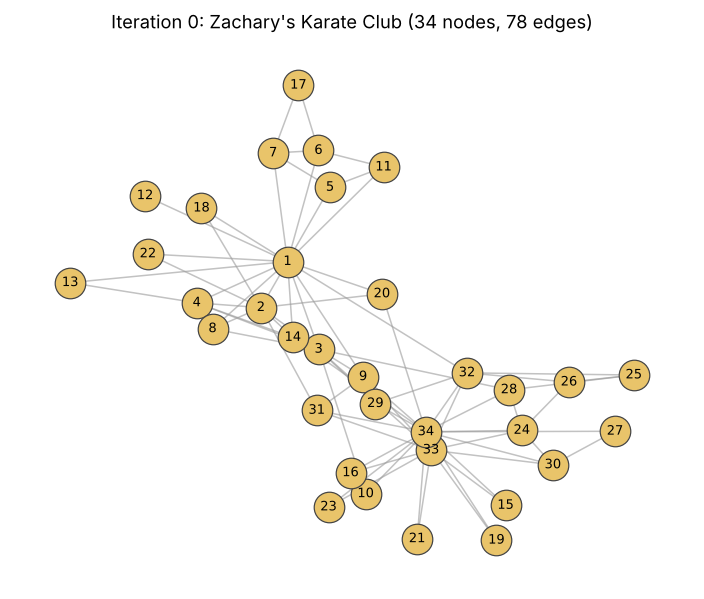

In [3]:
layout = nx.spring_layout(G, seed=42)       # one fixed layout reused for every figure

fig, ax = plt.subplots(figsize=(8, 6.5))
nx.draw_networkx_edges(G, layout, ax=ax, edge_color="#9a9a9a", alpha=0.6, width=1.0)
nx.draw_networkx_nodes(G, layout, ax=ax, node_color="#e9c46a", node_size=400, edgecolors="#444444", linewidths=0.8)
nx.draw_networkx_labels(G, layout, ax=ax, font_size=8.5)
ax.set_title("Iteration 0: Zachary's Karate Club (34 nodes, 78 edges)")
ax.axis("off")
plt.show()

## 6. Modularity: definitions

Let $A$ be the adjacency matrix, $k_i=\sum_jA_{ij}$ the degree of node $i$, $k$ the degree vector, $m$ the number of edges ($\sum_ik_i=2m$) and $n$ the number of nodes.

**Null model.** Give every node $i$ exactly $k_i$ half-edges and pair all $2m$ half-edges uniformly at random. A half-edge of $i$ lands on a half-edge of $j$ with probability $k_j/2m$, so the expected number of $i$–$j$ edges is $k_ik_j/2m$.

**Modularity matrix.**
$$
B \;=\; A-\frac{k\,k^{\top}}{2m},\qquad B_{ij}=A_{ij}-\frac{k_ik_j}{2m}.
$$
$A_{ij}$ is what is observed, $k_ik_j/2m$ is what chance alone predicts, and a positive $B_{ij}$ marks a pair that is tied more often than the degrees explain.

**Modularity of a two-way split.** For a vector $s\in\{+1,-1\}^n$ recording the side of every node,
$$
Q=\frac{1}{4m}\,s^{\top}B\,s .
$$

**Block matrix used to divide a community $C$.** The handout takes
$$
B^{(C)}=B[C,C],
$$
i.e. the rows and columns of the *global* $B$ that belong to $C$, with nothing added to the diagonal. This is the version run in Sections 7–20.

**Newman's generalised matrix (Section 21).** Newman (2006) shows that the gain in modularity from dividing a community $g$ is $\Delta Q=\frac1{4m}s^\top B^{(g)}s$ only if the block matrix is corrected on its diagonal:
$$
B^{(g)}_{ij}=B_{ij}-\delta_{ij}\sum_{k\in g}B_{ik},\qquad i,j\in g .
$$
The correction is introduced here so that its effect can be compared with the uncorrected block in the rest of the report.

## 7. Constructing $B$ and testing it

In [4]:
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)     # 0/1 adjacency
deg = A.sum(axis=1)                                       # degree vector k
null_model = np.outer(deg, deg) / (2 * M)                 # k k^T / 2m
B = A - null_model                                        # modularity matrix

checks = pd.Series({
    "shape of B": B.shape,
    "max |B - B^T|": np.abs(B - B.T).max(),
    "max |row sum of B|": np.abs(B.sum(axis=1)).max(),
    "1^T B 1": float(np.ones(N) @ B @ np.ones(N)),
})
print(checks.to_string())

assert set(np.unique(A)) <= {0.0, 1.0} and np.allclose(A, A.T) and A.sum() == 2 * M
assert np.allclose(deg, [G.degree(v) for v in nodes])
assert np.allclose(B, B.T) and np.allclose(B.sum(axis=1), 0.0)
print("\nEvery check on B passed.")

shape of B            (34, 34)
max |B - B^T|              0.0
max |row sum of B|         0.0
1^T B 1                    0.0

Every check on B passed.


$A$ and $kk^\top$ are both symmetric, hence so is $B$. Since $A\mathbf 1=k$ and $k^\top\mathbf 1=2m$, we get $B\mathbf 1=k-k=0$: every row of $B$ adds up to zero (Proposition 2 of the handout). It follows that one community holding every node has $Q=0$ (Corollary 1), which is the baseline that any cut must beat.

## 8. Leading eigenvector and the sign rule

Trying all $2^n$ sign vectors is hopeless, so the constraint $s\in\{\pm1\}^n$ is relaxed to real vectors with $\|s\|_2=1$. By the Rayleigh–Ritz theorem
$$
\max_{\|s\|_2=1}s^\top Bs=\lambda_1 ,
$$
attained at the eigenvector $u_1$ of the largest eigenvalue. Its entries are read as scores: a positive score places a node on one side, a non-positive score on the other,
$$
s_i=\begin{cases}+1,&(u_1)_i>0,\\-1,&(u_1)_i\le0.\end{cases}
$$
This rounding only approximates the best discrete split.

**Implementation notes**

* `np.linalg.eigh` handles symmetric matrices and returns eigenvalues in ascending order, so the leading pair is the last column.
* If $u$ is an eigenvector so is $-u$, which would just swap the group names. To make runs repeatable, the vector is multiplied by $\pm1$ so that its largest-magnitude entry is positive.

In [5]:
def sub_block(Mat, members):
    # rows/columns of a global matrix that belong to `members`
    ix = [row_of[v] for v in members]
    return Mat[np.ix_(ix, ix)]

def top_eigpair(Mat):
    # largest eigenvalue and its eigenvector, sign-fixed so the biggest entry is positive
    vals, vecs = np.linalg.eigh(Mat)
    lam, vec = vals[-1], vecs[:, -1]
    return lam, vec * np.sign(vec[np.argmax(np.abs(vec))])

def modularity_of(parts):
    # Q = (1/2m) * sum over parts of the sum of B_ij inside each part
    return sum(sub_block(B, p).sum() for p in parts) / (2 * M)

lam_whole, vec_whole = top_eigpair(B)
s_whole = np.where(vec_whole > 0, 1, -1)
plus_side  = [v for v, s in zip(nodes, s_whole) if s == 1]
minus_side = [v for v, s in zip(nodes, s_whole) if s == -1]

print(f"largest eigenvalue of B        : {lam_whole:.4f}")
print(f"sizes of the +1 / -1 sides     : {len(plus_side)} / {len(minus_side)}")
print(f"Q via s^T B s / 4m             : {s_whole @ B @ s_whole / (4 * M):.4f}")
print(f"Q via group-sum formula        : {modularity_of([plus_side, minus_side]):.4f}")
assert np.isclose(s_whole @ B @ s_whole / (4 * M), modularity_of([plus_side, minus_side]))

largest eigenvalue of B        : 4.9771
sizes of the +1 / -1 sides     : 16 / 18
Q via s^T B s / 4m             : 0.3715
Q via group-sum formula        : 0.3715


## 9. The Recursive Splitting Process

For each community \(C\), the algorithm follows these steps:

1. Build its block matrix and find the largest eigenvalue and its corresponding eigenvector.
2. If the largest eigenvalue is zero or negative, stop splitting that community.
3. Otherwise, divide the nodes into two groups based on the positive and negative signs of the eigenvector.
4. If one group is empty, the split is invalid, so stop.
5. If both groups are non-empty, accept the split and repeat the process for each group.

A community with only one node is not split. The process ends when no further valid splits are possible.

**Implementation:** A stack is used to keep track of communities that still need to be checked. Each community is stored in a dictionary called `parts`. After every accepted split, the updated partition and its modularity are saved. Each attempt is also recorded.

The function has a `newman` switch:
- `newman=False`: Uses the original block matrix \(B[C,C]\).
- `newman=True`: Uses Newman's corrected block matrix and accepts a split only if its exact modularity change is positive.

The corrected method is used later in Section 21. For every accepted split, the algorithm records the calculated modularity change and the actual modularity of the resulting partition.

In [6]:
TOL = 1e-10

def split_block(members, newman):
    """Matrix used to split `members`.
    newman=False : B[C, C]                              (the handout's matrix)
    newman=True  : B[C, C] - diag(row sums of B[C, C])  (Newman's generalised matrix)"""
    Bc = sub_block(B, members)
    return Bc - np.diag(Bc.sum(axis=1)) if newman else Bc

def recursive_split(newman=False):
    parts = {0: list(nodes)}
    spare_id = 1
    history = [{"step": 0, "parts": {0: list(nodes)}, "Q": modularity_of(parts.values())}]
    tries = []
    todo = [0]

    while todo:
        cid = todo.pop()
        members = parts[cid]
        rec = {"try": len(tries) + 1, "community": cid, "size": len(members), "lambda_1": np.nan,
               "dQ_formula": np.nan, "step": None, "children": None, "outcome": ""}
        tries.append(rec)

        if len(members) < 2:
            rec["outcome"] = "single node, nothing to split"
            continue

        Mc = split_block(members, newman)
        lam, vec = top_eigpair(Mc)
        rec["lambda_1"] = lam
        if lam <= TOL:
            rec["outcome"] = "stop: leading eigenvalue not positive"
            continue

        s = np.where(vec > 0, 1, -1)
        pos = [v for v, x in zip(members, s) if x == 1]
        neg = [v for v, x in zip(members, s) if x == -1]
        if not pos or not neg:
            rec["outcome"] = "stop: degenerate sign split (one side empty)"
            continue

        rec["dQ_formula"] = s @ Mc @ s / (4 * M)
        if newman and rec["dQ_formula"] <= TOL:
            rec["outcome"] = "stop: sign cut would not raise Q"
            continue

        low, high = sorted([pos, neg], key=min)          # side with the smallest label keeps the id
        new_id, spare_id = spare_id, spare_id + 1
        parts[cid], parts[new_id] = sorted(low), sorted(high)

        step = len(history)
        history.append({"step": step, "parts": {c: list(g) for c, g in parts.items()},
                        "Q": modularity_of(parts.values())})
        rec.update(step=step, children=((cid, sorted(low)), (new_id, sorted(high))), outcome="split accepted")
        todo.extend([new_id, cid])
    return history, tries

snaps, tries = recursive_split(newman=False)       # the handout's matrix B[C, C]
print("handout variant:", len(snaps) - 1, "accepted cuts,", len(snaps[-1]["parts"]), "final communities")

handout variant: 4 accepted cuts, 5 final communities


## 10. Running the procedure and reading the log

In [7]:
def show_log(tries):
    t = pd.DataFrame(tries)
    t["children (sizes)"] = t["children"].apply(lambda c: "" if c is None else f"{len(c[0][1])} + {len(c[1][1])}")
    t["step"] = t["step"].apply(lambda x: "-" if pd.isna(x) else str(int(x)))
    print(t[["try", "step", "community", "size", "lambda_1", "dQ_formula", "children (sizes)", "outcome"]]
          .to_string(index=False, float_format=lambda x: f"{x:.4f}", na_rep="-"))
    print("\nAccepted cuts:")
    for r in tries:
        if r["step"] is not None:
            (c_lo, g_lo), (c_hi, g_hi) = r["children"]
            print(f"  step {r['step']}: community {r['community']} (size {r['size']})")
            print(f"      keeps id {c_lo}: {g_lo}")
            print(f"      new id   {c_hi}: {g_hi}")

def show_summary(snaps):
    s = pd.DataFrame({
        "communities": [len(x["parts"]) for x in snaps],
        "sizes": [sorted((len(g) for g in x["parts"].values()), reverse=True) for x in snaps],
        "Q": [x["Q"] for x in snaps],
    }, index=pd.Index([x["step"] for x in snaps], name="step"))
    s["Q"] = s["Q"].where(s["Q"].abs() > 1e-12, 0.0).round(4)
    print(s.to_string())

def verify_run(snaps, tries, must_increase=True):
    for x in snaps:
        members = [v for g in x["parts"].values() for v in g]
        assert sorted(members) == nodes, "a node was lost or duplicated"
        assert all(len(g) > 0 for g in x["parts"].values())
        assert len(x["parts"]) == x["step"] + 1
    for r in tries:
        if r["step"] is not None:
            (_, g1), (_, g2) = r["children"]
            assert g1 and g2 and sorted(g1 + g2) == sorted(snaps[r["step"] - 1]["parts"][r["community"]])
    Qs = np.array([x["Q"] for x in snaps])
    if must_increase:
        assert np.isclose(Qs[0], 0.0) and np.all(np.diff(Qs) > 0), "Q must grow with every accepted cut"
    return Qs

show_log(tries)
print()
show_summary(snaps)
Q_handout = verify_run(snaps, tries)
final_parts = snaps[-1]["parts"]
last_step = snaps[-1]["step"]
print(f"\nChecks passed. Accepted cuts: {last_step}; final communities: {len(final_parts)}; final Q = {Q_handout[-1]:.4f}")

 try step  community  size  lambda_1  dQ_formula children (sizes)                                      outcome
   1    1          0    34    4.9771      0.3715          16 + 18                               split accepted
   2    2          0    16    2.9441      0.1112           10 + 6                               split accepted
   3    -          0    10    2.5712           -                  stop: degenerate sign split (one side empty)
   4    3          2     6    2.1480      0.0338            5 + 1                               split accepted
   5    -          2     5    2.1470           -                  stop: degenerate sign split (one side empty)
   6    -          3     1         -           -                                 single node, nothing to split
   7    4          1    18    2.5041      0.1112           13 + 5                               split accepted
   8    -          1    13    2.3563           -                  stop: degenerate sign split (one side empty)
 

## 11. The network after every accepted cut

Each picture shows the whole graph at the Section 5 positions, with nodes coloured by current community. A community keeps its colour while it exists; when it splits, the half with the smallest label keeps the colour and the other half takes a new one.

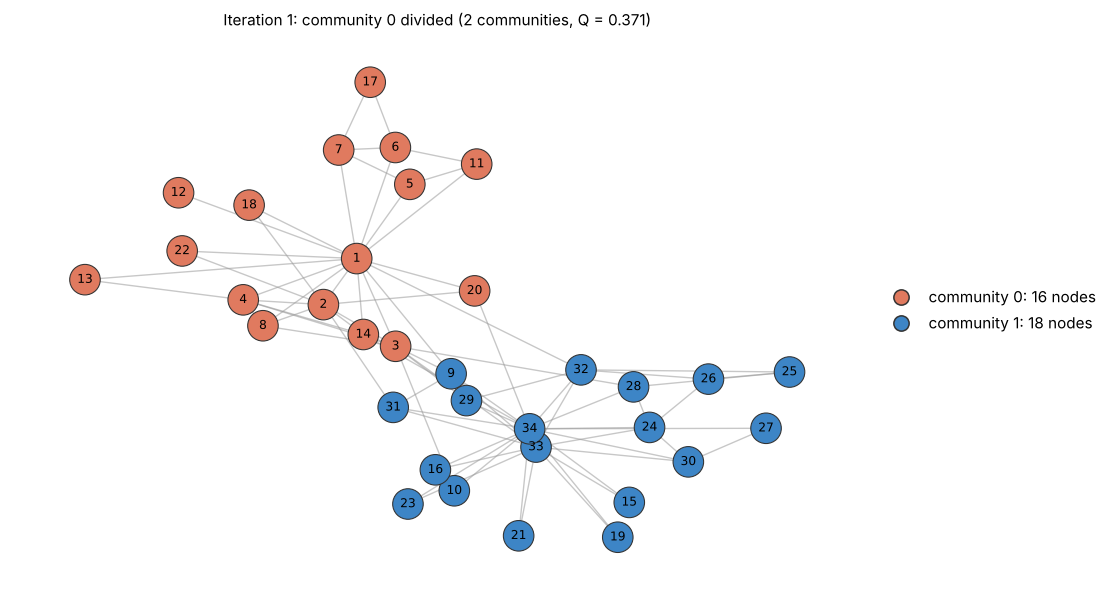

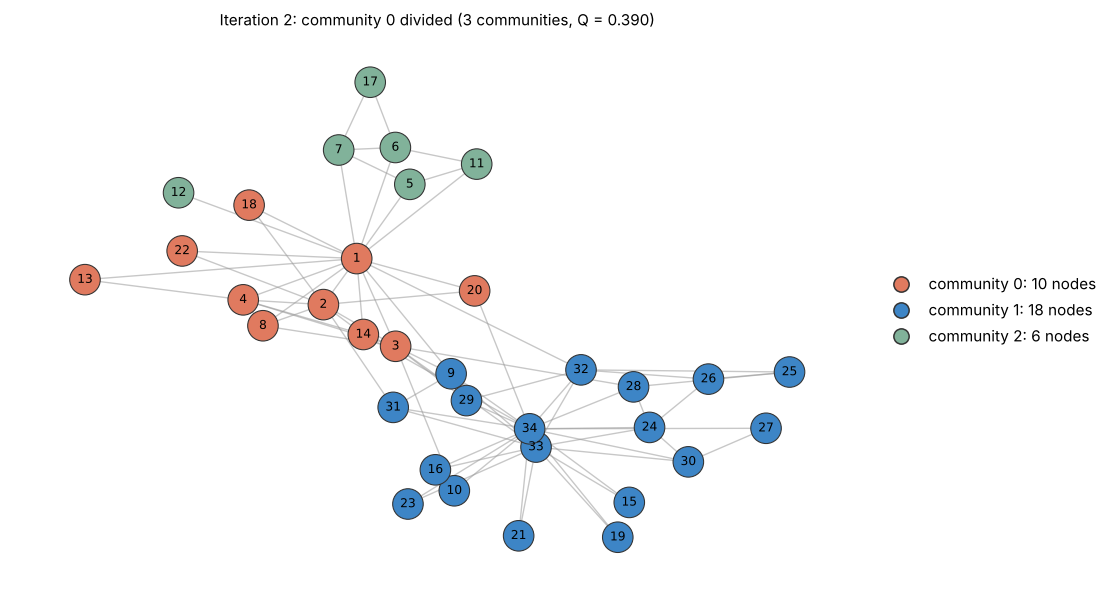

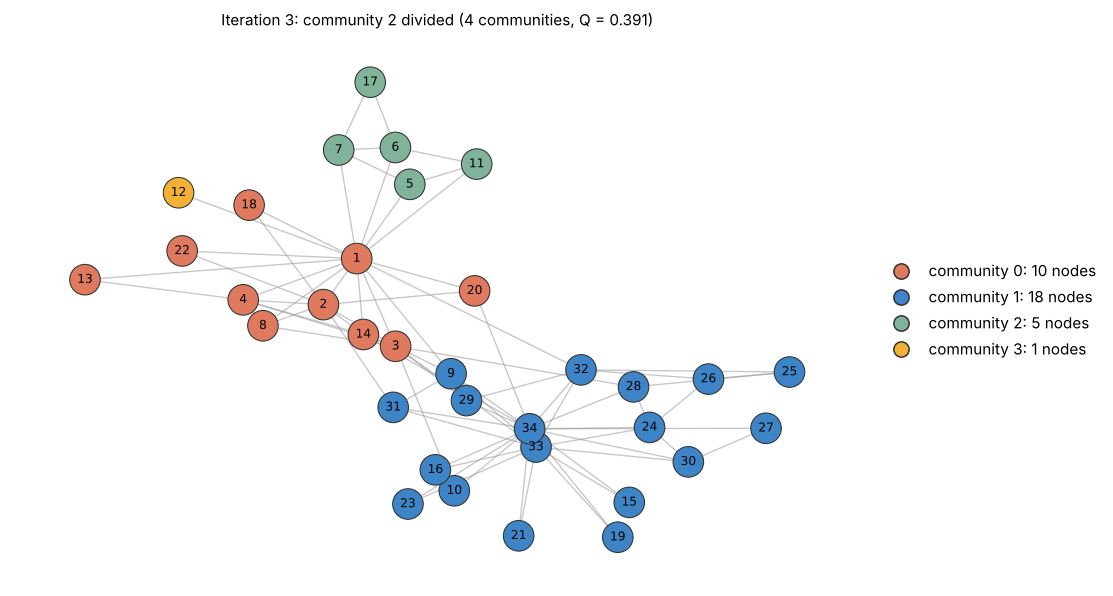

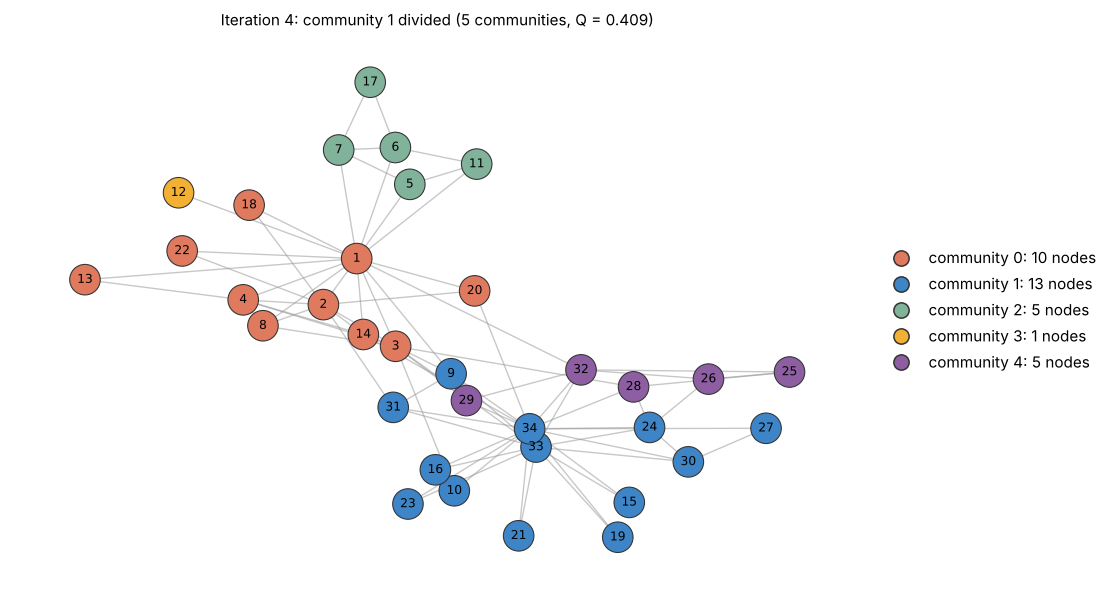

In [8]:
PALETTE = ["#e07a5f", "#3d85c6", "#81b29a", "#f2b134", "#8e5ea2", "#4d908e", "#b5838d", "#6d6875"]

def paint(parts, title, ax=None, sizes=None, labels=True):
    color_of = {v: PALETTE[cid % len(PALETTE)] for cid, g in parts.items() for v in g}
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(10, 6.5))
    nx.draw_networkx_edges(G, layout, ax=ax, edge_color="#9a9a9a", alpha=0.55, width=0.9)
    nx.draw_networkx_nodes(G, layout, ax=ax, nodelist=nodes, node_color=[color_of[v] for v in nodes],
                           node_size=400 if sizes is None else [sizes[v] for v in nodes],
                           edgecolors="#333333", linewidths=0.7)
    if labels:
        nx.draw_networkx_labels(G, layout, ax=ax, font_size=8 if sizes is None else 6.5)
    if own:
        handles = [plt.Line2D([], [], marker="o", ls="", markerfacecolor=PALETTE[cid % len(PALETTE)],
                              markeredgecolor="#333333", markersize=10, label=f"community {cid}: {len(g)} nodes")
                   for cid, g in parts.items()]
        ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
    if own:
        plt.show()

def draw_all_cuts(snaps, tries):
    for r in tries:
        if r["step"] is not None:
            x = snaps[r["step"]]
            paint(x["parts"], f"Iteration {r['step']}: community {r['community']} divided "
                              f"({len(x['parts'])} communities, Q = {x['Q']:.3f})")

draw_all_cuts(snaps, tries)

## 12. Node metrics: method

### Centrality Measures

We calculate four network metrics using NetworkX. Each metric describes a different aspect of a node's importance in the network.

**1. Degree Centrality (`nx.degree_centrality`)**

Measures how many other nodes are directly connected to a node.

Formula: $C_D(i)=\dfrac{k_i}{r-1}$, $r$

Here, `ki` is the number of connections of node `i`, and `r` is the total number of nodes in the community.

**2. Betweenness Centrality (`nx.betweenness_centrality`)**

Measures how often a node lies on the shortest paths between other pairs of nodes. A higher value indicates that the node acts as an important link between different parts of the network.

Formula: $C_B(i)=\sum_{s\ne i\ne t}\dfrac{\sigma_{st}(i)}{\sigma_{st}}$

Here, `σst` is the total number of shortest paths between nodes `s` and `t`, and `σst(i)` is the number of those paths passing through node `i`. NetworkX applies normalization.

**3. Closeness Centrality (`nx.closeness_centrality`)**

Measures how close a node is to all other reachable nodes. A higher value means that the node can reach other nodes through shorter paths.

Formula: $C_C(i)=\dfrac{r-1}{\sum_{j\ne i}d(i,j)}$

Here, `d(i,j)` is the shortest-path distance between nodes `i` and `j`.

**4. Clustering Coefficient (`nx.clustering`)**

Measures how strongly a node's neighbours are connected to one another. A higher value means that more of its neighbours are also connected.

Formula: $C(i)=\dfrac{2T(i)}{k_i(k_i-1)}$

Here, `T(i)` is the number of triangles involving node `i`, and `ki` is its degree.

### Why Calculate Metrics Within Each Community?

When a network is divided into communities, its original edges remain unchanged. Therefore, calculating these metrics on the complete graph at every iteration would give the same values.

To study how node importance changes during partitioning, we calculate all four metrics within each node's current community, using the subgraph formed by that community.

- **Iteration 0:** Metrics are calculated for the complete graph. These values act as the baseline.
- **Later iterations:** Metrics are recalculated within each node's current community.
- **Final iteration:** Metrics are calculated within the final detected communities.

As communities become smaller, the metrics may change. This reflects the node's position within its community, not a change in the original network.

### Special Cases

- **Single-node communities:** All four metrics are assigned a value of 0 because degree and closeness centrality are not meaningful for a single-node community.
- **Disconnected communities:** NetworkX calculates closeness centrality using only reachable nodes, with Wasserman–Faust scaling. These communities are also identified in the output.

In [9]:
METRICS = {
    "degree":      nx.degree_centrality,
    "betweenness": nx.betweenness_centrality,
    "closeness":   nx.closeness_centrality,
    "clustering":  nx.clustering,
}
METRIC_LABEL = {"degree": "degree centrality", "betweenness": "betweenness centrality",
                "closeness": "closeness centrality", "clustering": "clustering coefficient"}

def metrics_inside(H):
    if H.number_of_nodes() == 1:                       # one-node community: all four set to 0
        (only,) = H.nodes
        return {name: {only: 0.0} for name in METRICS}
    return {name: fn(H) for name, fn in METRICS.items()}

def collect_history(snaps):
    rows, broken = [], []
    for x in snaps:
        for cid, members in x["parts"].items():
            H = G.subgraph(members)
            if not nx.is_connected(H):
                broken.append((x["step"], cid))
            for name, vals in metrics_inside(H).items():
                for v, val in vals.items():
                    rows.append((x["step"], cid, v, name, float(val)))
    long_df = (pd.DataFrame(rows, columns=["step", "community", "node", "metric", "value"])
                 .sort_values(["step", "metric", "node"]).reset_index(drop=True))
    wide_tabs = {name: long_df[long_df.metric == name].pivot(index="node", columns="step", values="value")
                 for name in METRICS}
    return long_df, wide_tabs, broken

long_h, tab_h, broken_h = collect_history(snaps)
print("iterations with metrics:", [x["step"] for x in snaps])
print("disconnected induced communities (step, id):", broken_h or "none")

iterations with metrics: [0, 1, 2, 3, 4]
disconnected induced communities (step, id): [(2, 2)]


## 13. The metric history table

Everything is first stored in one long table with a row per (iteration, node, metric). One *wide* table per metric (nodes as rows, iterations as columns) is derived from it, and the evolution tables, plots and comparisons below all read from these wide tables.

In [10]:
final_label = pd.Series({v: cid for cid, g in final_parts.items() for v in g}).sort_index()

print("first rows of the long table:")
print(long_h.head(6).to_string())
print("\nrandom sample of 6 rows (seed 0):")
print(long_h.sample(6, random_state=0).sort_index().to_string())

assert len(long_h) == len(snaps) * N * len(METRICS)
assert not long_h.duplicated(["step", "node", "metric"]).any()
assert long_h.value.between(0, 1).all()
for name, fn in METRICS.items():
    assert np.allclose(tab_h[name][0].values, pd.Series(fn(G)).sort_index().values), f"baseline differs: {name}"
    for members in final_parts.values():
        got = tab_h[name].loc[members, last_step].values
        want = np.zeros(1) if len(members) == 1 else pd.Series(fn(G.subgraph(members))).loc[members].values
        assert np.allclose(got, want), f"final values differ: {name}"
print(f"\n{len(long_h)} rows = {len(snaps)} iterations x {N} nodes x {len(METRICS)} metrics. Checks passed.")

first rows of the long table:
   step  community  node       metric     value
0     0          0     1  betweenness  0.437635
1     0          0     2  betweenness  0.053937
2     0          0     3  betweenness  0.143657
3     0          0     4  betweenness  0.011909
4     0          0     5  betweenness  0.000631
5     0          0     6  betweenness  0.029987

random sample of 6 rows (seed 0):
     step  community  node       metric     value
113     0          0    12       degree  0.030303
157     1          0    22  betweenness  0.000000
306     2          0     1    closeness  1.000000
313     2          0     8    closeness  0.642857
422     3          1    15  betweenness  0.000000
591     4          0    14    closeness  0.642857

680 rows = 5 iterations x 34 nodes x 4 metrics. Checks passed.


## 14–17. Evolution of the four metrics

Each of the next four sections has the same layout:

1. **Complete table** — all 34 nodes, every iteration, with the community id the node belongs to at that iteration (`comm@t`);
2. **Summary per iteration** — mean, median, maximum (and who holds it), minimum, and the number of nodes at exactly 0;
3. **Step-to-step movement** — for each iteration, the node with the biggest rise, the node with the biggest fall, and how many nodes rose, fell or stayed the same;
4. **Figures** — (left) one line per node, coloured by the node's final community, with eight focus nodes (hubs 1, 33, 34; connectors 2, 3, 32; node 25; and node 12, which ends up alone) drawn thick; (right) the same values as a heat map; below, the network at every iteration with node *area* proportional to the metric;
5. **Reading the evolution** — a short written interpretation tied to the printed numbers.

In [11]:
FOCUS = [1, 2, 3, 12, 25, 32, 33, 34]

def community_at(snaps, step):
    return pd.Series({v: cid for cid, g in snaps[step]["parts"].items() for v in g}).sort_index()

def lines_panel(ax, table, ylabel, snaps, focus=FOCUS, title=None, legend=True):
    final_lab = community_at(snaps, snaps[-1]["step"])
    steps = list(table.columns)
    for v in nodes:
        emph = v in focus
        ax.plot(steps, table.loc[v].values, color=PALETTE[final_lab[v] % len(PALETTE)],
                lw=2.4 if emph else 0.9, alpha=1.0 if emph else 0.38,
                marker="o", ms=4.2 if emph else 2.2, zorder=3 if emph else 2)
    ends = sorted((table.loc[v, steps[-1]], v) for v in focus)
    gap = 0.045 * max(table.values.max() - table.values.min(), 1e-9)
    ypos, last = {}, -np.inf
    for y, v in ends:
        last = max(y, last + gap)
        ypos[v] = last
    for v in focus:
        ax.annotate(str(v), xy=(steps[-1], table.loc[v, steps[-1]]), xytext=(steps[-1] + 0.12, ypos[v]),
                    va="center", fontsize=8.5, fontweight="bold", color=PALETTE[final_lab[v] % len(PALETTE)],
                    arrowprops=dict(arrowstyle="-", color="#bbbbbb", lw=0.6))
    if legend:
        hs = [plt.Line2D([], [], color=PALETTE[c % len(PALETTE)], lw=3, label=f"final community {c} ({len(g)} nodes)")
              for c, g in snaps[-1]["parts"].items()]
        ax.legend(handles=hs, loc="upper left", frameon=False, fontsize=8)
    ax.set_xticks(steps)
    ax.set_xlim(steps[0] - 0.15, steps[-1] + 0.6)
    ax.set_xlabel("iteration (0 = whole graph)")
    ax.set_ylabel(ylabel)
    if title:
        ax.set_title(title, fontsize=10)
    ax.grid(axis="y", color="#e2e2e2")
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

def heat_panel(ax, table, title):
    im = ax.imshow(table.values, aspect="auto", cmap="viridis", vmin=0, vmax=1)
    ax.set_xticks(range(table.shape[1]))
    ax.set_xticklabels(table.columns)
    ax.set_yticks(range(table.shape[0]))
    ax.set_yticklabels(table.index, fontsize=7)
    ax.set_xlabel("iteration")
    ax.set_title(title, fontsize=10)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            val = table.values[i, j]
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=5.5,
                    color="white" if val < 0.55 else "black")
    return im

def evolution_figure(name, tab, snaps, tag=""):
    fig = plt.figure(figsize=(16, 9.5))
    gs = fig.add_gridspec(1, 2, width_ratios=[1.55, 1], wspace=0.18)
    ax1, ax2 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
    lines_panel(ax1, tab, METRIC_LABEL[name], snaps,
                title=f"{METRIC_LABEL[name].capitalize()}: path of every node {tag}")
    im = heat_panel(ax2, tab, "same values as a heat map (rows = nodes)")
    fig.colorbar(im, ax=ax2, fraction=0.035, pad=0.02)
    plt.show()

def size_strip(name, tab, snaps, tag=""):
    # network at every iteration; node area is proportional to the metric, colour = community at that iteration
    top = max(tab.values.max(), 1e-9)
    cols = len(snaps)
    fig, axes = plt.subplots(1, cols, figsize=(4.6 * cols, 4.6))
    for ax, x in zip(np.atleast_1d(axes), snaps):
        sizes = {v: 30 + 620 * tab.loc[v, x["step"]] / top for v in nodes}
        paint(x["parts"], f"iteration {x['step']}  ({len(x['parts'])} comm.)", ax=ax, sizes=sizes)
    fig.suptitle(f"{METRIC_LABEL[name].capitalize()}: node area proportional to the value {tag}", y=1.02, fontsize=12)
    plt.tight_layout()
    plt.show()

def evolution_table(name, tab, snaps):
    # complete table: all 34 nodes, every iteration, plus the community id the node has at that iteration
    out = tab.copy()
    out.columns = [f"it {c}" for c in out.columns]
    for x in snaps:
        lab = community_at(snaps, x["step"])
        out[f"comm@{x['step']}"] = lab
    return out

def evolution_digest(name, tab, snaps):
    steps = list(tab.columns)
    d = pd.DataFrame({
        "mean": tab.mean(), "median": tab.median(), "max": tab.max(),
        "node with max": tab.idxmax(), "min": tab.min(), "nodes at 0": (tab < 1e-9).sum(),
    })
    d["mean"] = d["mean"].round(3); d["median"] = d["median"].round(3)
    d["max"] = d["max"].round(3); d["min"] = d["min"].round(3)
    d.index.name = "iteration"
    delta = tab.diff(axis=1)
    moves = []
    for s in steps[1:]:
        up, down = delta[s].idxmax(), delta[s].idxmin()
        up_txt, up_val = (up, round(delta.loc[up, s], 3)) if delta.loc[up, s] > 1e-9 else ("-", 0.0)
        dn_txt, dn_val = (down, round(delta.loc[down, s], 3)) if delta.loc[down, s] < -1e-9 else ("-", 0.0)
        moves.append((s, up_txt, up_val, dn_txt, dn_val,
                      int((delta[s] > 1e-9).sum()), int((delta[s] < -1e-9).sum()), int((delta[s].abs() <= 1e-9).sum())))
    mv = pd.DataFrame(moves, columns=["iteration", "largest rise: node", "by", "largest fall: node", "by",
                                      "# rose", "# fell", "# same"]).set_index("iteration")
    return d, mv

def metric_block(name, tab, snaps, tag=""):
    print(f"=== {METRIC_LABEL[name].upper()}  ({tag or 'handout matrix'}): value of all 34 nodes at every iteration ===")
    print(evolution_table(name, tab, snaps).round(3).to_string())
    d, mv = evolution_digest(name, tab, snaps)
    print("\nsummary per iteration:")
    print(d.to_string())
    print("\nstep-to-step movement (iteration t compared with t-1):")
    print(mv.to_string())

### 14. Degree centrality

In [12]:
metric_block("degree", tab_h["degree"], snaps)

=== DEGREE CENTRALITY  (handout matrix): value of all 34 nodes at every iteration ===
       it 0   it 1   it 2   it 3   it 4  comm@0  comm@1  comm@2  comm@3  comm@4
node                                                                           
1     0.485  0.933  1.000  1.000  1.000       0       0       0       0       0
2     0.273  0.533  0.889  0.889  0.889       0       0       0       0       0
3     0.303  0.333  0.556  0.556  0.556       0       0       0       0       0
4     0.182  0.400  0.667  0.667  0.667       0       0       0       0       0
5     0.091  0.200  0.400  0.500  0.500       0       0       2       2       2
6     0.121  0.267  0.600  0.750  0.750       0       0       2       2       2
7     0.121  0.267  0.600  0.750  0.750       0       0       2       2       2
8     0.121  0.267  0.444  0.444  0.444       0       0       0       0       0
9     0.152  0.176  0.176  0.176  0.250       0       1       1       1       1
10    0.061  0.059  0.059  0.059  

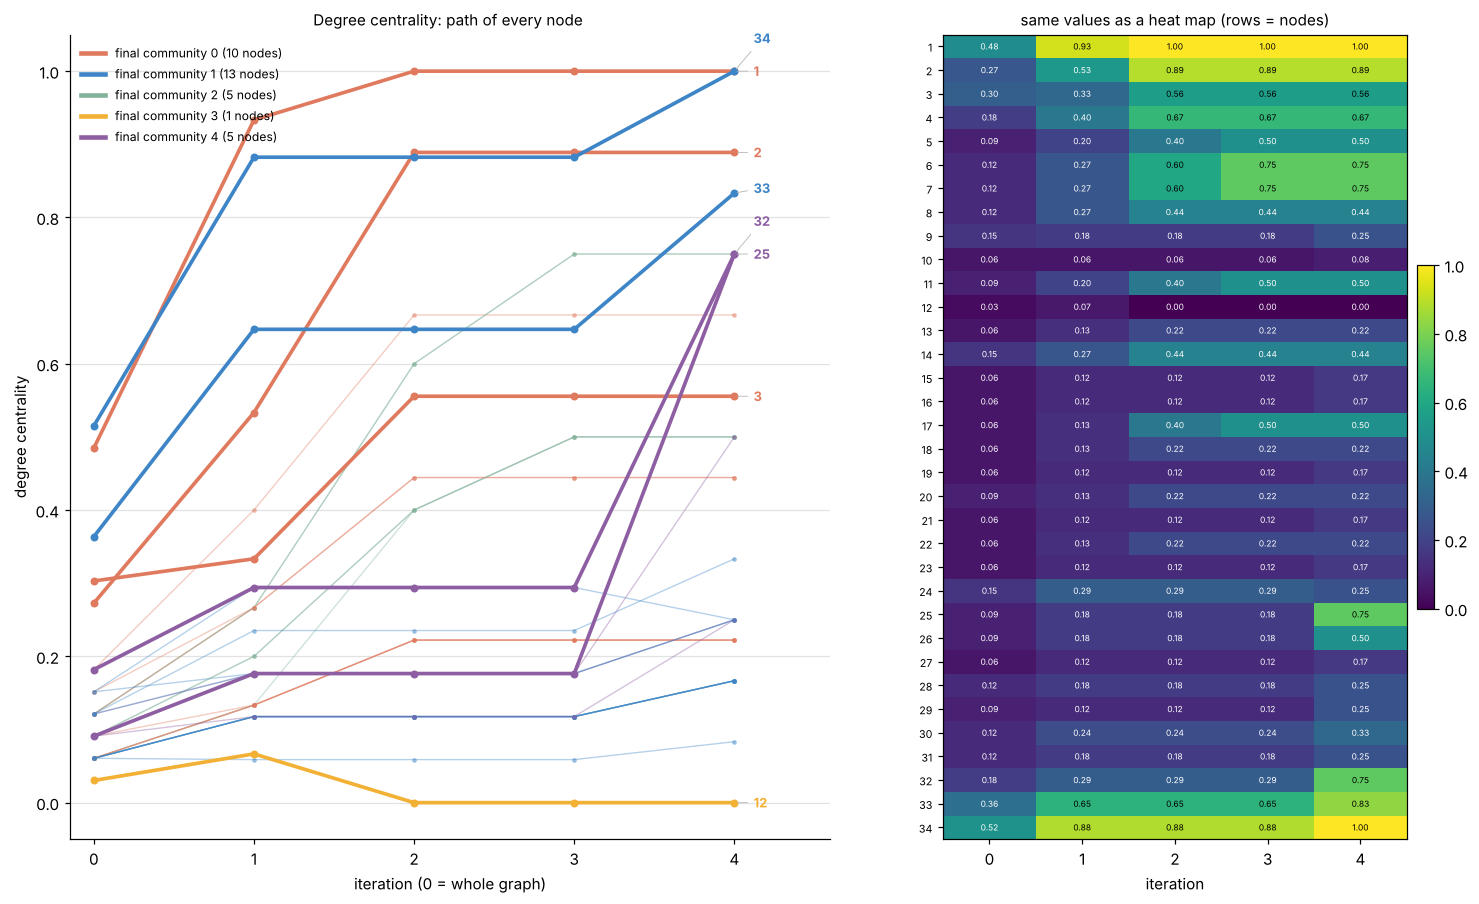

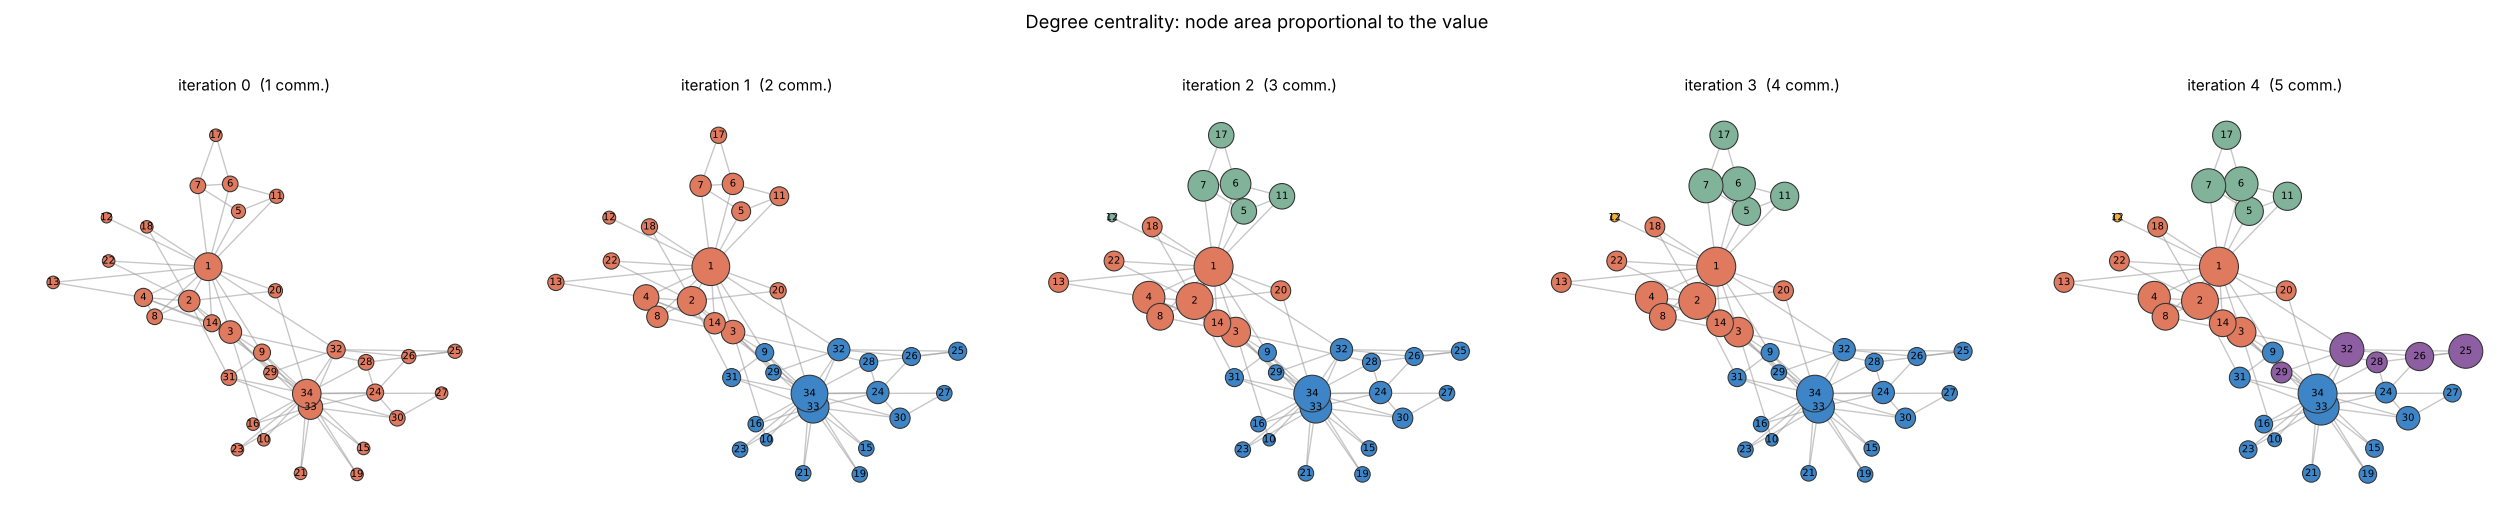

In [13]:
evolution_figure("degree", tab_h["degree"], snaps)
size_strip("degree", tab_h["degree"], snaps)

**Reading the evolution of degree centrality**

* **Average:** 0.139 → 0.251 → 0.335 → 0.353 → 0.423. It climbs at every iteration because each cut shrinks $r-1$ and most of a node's neighbours stay with it.
* **Iteration 1 (34 → 16 + 18):** 33 nodes rise and only node 10 dips (−0.002). The leaders swap places: node 34 (0.515) led the whole graph, but inside their halves node 1 (0.933) and node 34 (0.882) are the top two.
* **Iteration 2 (16 → 10 + 6):** the 18-node community is untouched, so its 18 members do not move. Node 2 gains most (+0.356). Node 12 falls to 0, because its single neighbour, node 1, is in the other half.
* **Iteration 3 (6 → 5 + 1):** only the five nodes of $\{5,6,7,11,17\}$ move (gains up to +0.150), because the isolated node 12 leaves their group; the other 29 nodes keep their values.
* **Iteration 4 (18 → 13 + 5):** 17 nodes rise, the five members of $\{25,26,28,29,32\}$ most of all (node 25: +0.574); node 24 slips by 0.044, the only fall.
* **Hubs:** node 1 reaches 1.0 at iteration 2 and node 34 reaches 1.0 at iteration 4 — each knows every other member of its final community.

### 15. Betweenness centrality

In [14]:
metric_block("betweenness", tab_h["betweenness"], snaps)

=== BETWEENNESS CENTRALITY  (handout matrix): value of all 34 nodes at every iteration ===
       it 0   it 1   it 2   it 3   it 4  comm@0  comm@1  comm@2  comm@3  comm@4
node                                                                           
1     0.438  0.690  0.354  0.354  0.354       0       0       0       0       0
2     0.054  0.074  0.215  0.215  0.215       0       0       0       0       0
3     0.144  0.002  0.007  0.007  0.007       0       0       0       0       0
4     0.012  0.021  0.062  0.062  0.062       0       0       0       0       0
5     0.001  0.003  0.050  0.083  0.083       0       0       2       2       2
6     0.030  0.065  0.150  0.250  0.250       0       0       2       2       2
7     0.030  0.065  0.150  0.250  0.250       0       0       2       2       2
8     0.000  0.000  0.000  0.000  0.000       0       0       0       0       0
9     0.056  0.000  0.000  0.000  0.000       0       1       1       1       1
10    0.001  0.000  0.000  0.

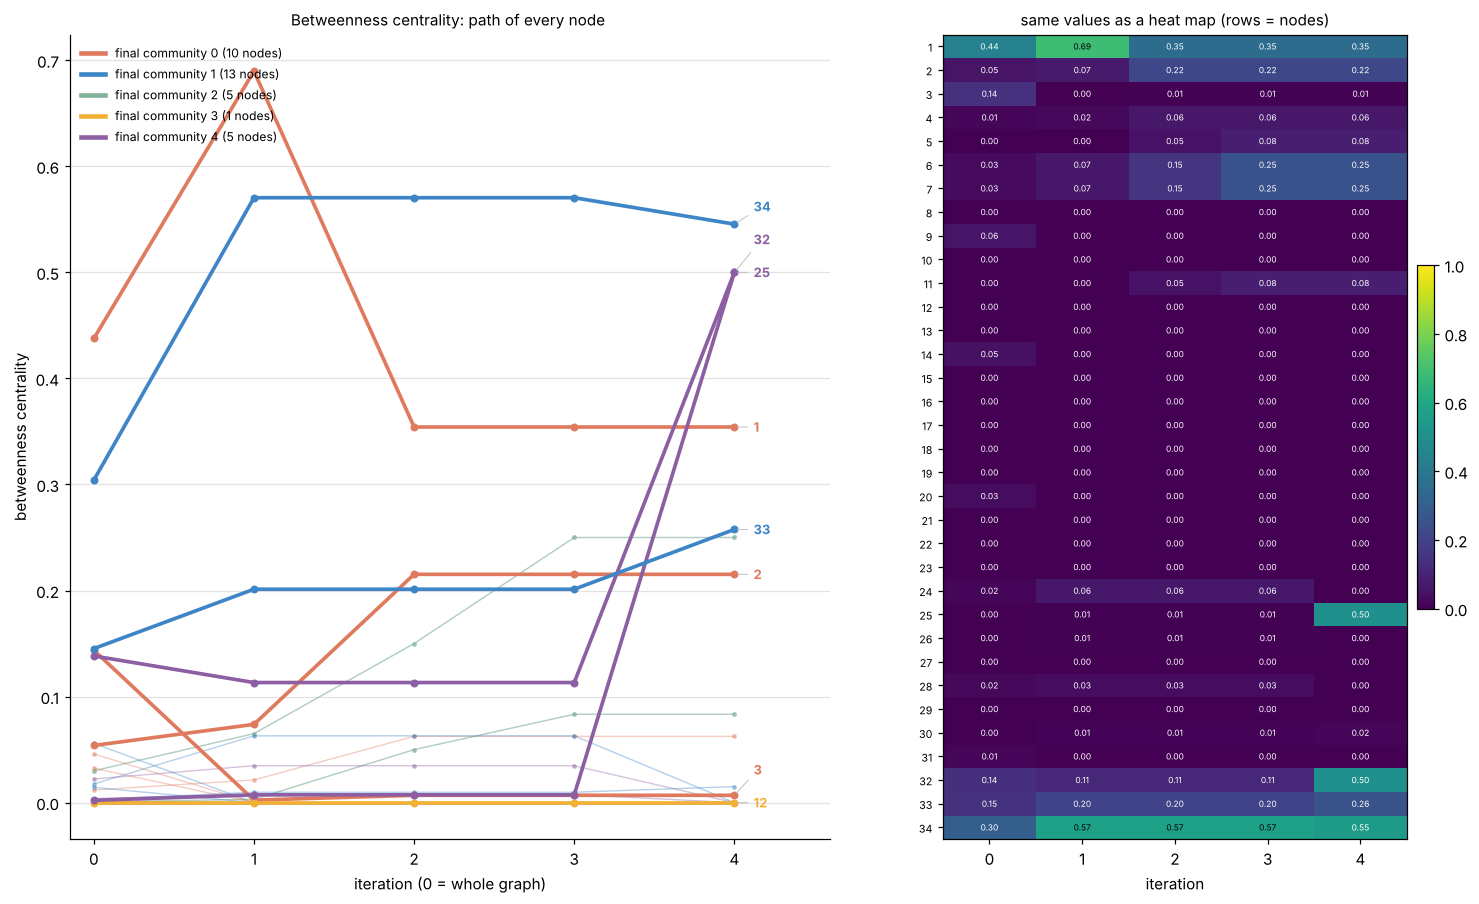

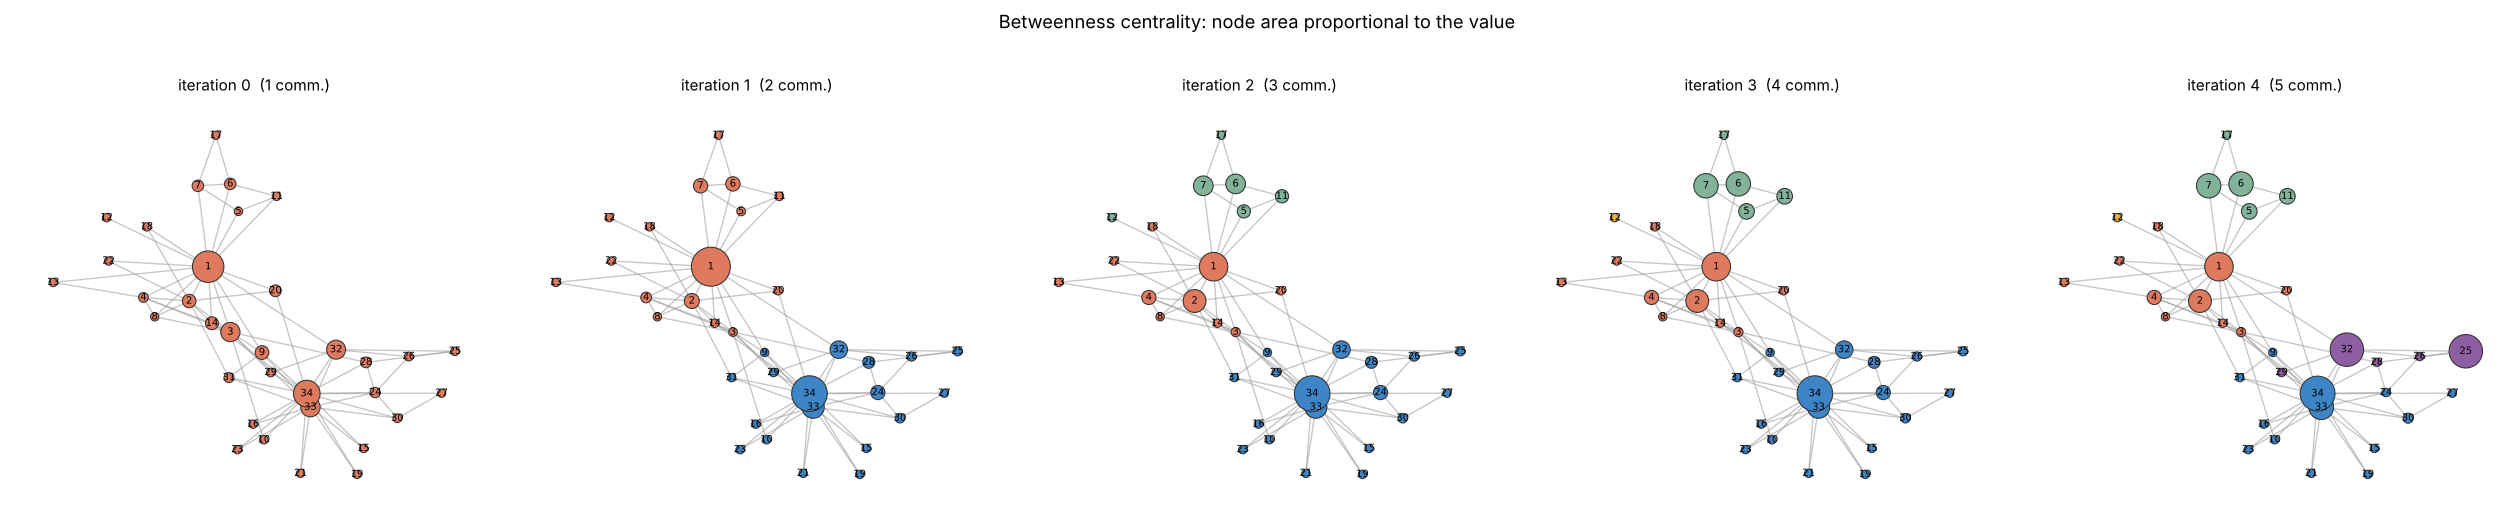

In [15]:
evolution_figure("betweenness", tab_h["betweenness"], snaps)
size_strip("betweenness", tab_h["betweenness"], snaps)

**Reading the evolution of betweenness centrality**

* **Average:** 0.044 → 0.057 → 0.060 → 0.068 → 0.092, with the count of nodes at exactly 0 going 12 → 18 → 18 → 18 → 21. Betweenness concentrates in a few brokers.
* **Iteration 1:** the picture is mixed: 14 nodes rise, 8 fall, 12 stay the same. Node 34 gains most (+0.266), node 3 loses most (−0.141): half of its neighbours (9, 10, 28, 29, 33) are in the other community, so the routes that went through it are gone.
* **Iteration 2:** node 1 falls from 0.690 to 0.354 (−0.336), because nodes 5, 6, 7, 11, 12 and 17 have left its community; node 34 (0.570) becomes the leader. Node 2 gains most (+0.141).
* **Iteration 3:** only four nodes change (nodes 6 and 7 rise by 0.100 each to 0.250).
* **Iteration 4:** in the 5-node group $\{25,26,28,29,32\}$ nodes 25 and 32 become the two brokers (0.5 each, up from 0.007 and 0.113). Node 34 stays top with 0.545.
* **Over the whole run:** 11 nodes end higher than in the full graph, 11 end lower, and 12 never move; nine nodes (9, 10, 14, 20, 24, 26, 28, 29, 31) go from a positive value to exactly 0.

### 16. Closeness centrality

In [16]:
metric_block("closeness", tab_h["closeness"], snaps)

=== CLOSENESS CENTRALITY  (handout matrix): value of all 34 nodes at every iteration ===
       it 0   it 1   it 2   it 3   it 4  comm@0  comm@1  comm@2  comm@3  comm@4
node                                                                           
1     0.569  0.938  1.000  1.000  1.000       0       0       0       0       0
2     0.485  0.652  0.900  0.900  0.900       0       0       0       0       0
3     0.559  0.577  0.692  0.692  0.692       0       0       0       0       0
4     0.465  0.600  0.750  0.750  0.750       0       0       0       0       0
5     0.379  0.556  0.533  0.667  0.667       0       0       2       2       2
6     0.384  0.577  0.640  0.800  0.800       0       0       2       2       2
7     0.384  0.577  0.640  0.800  0.800       0       0       2       2       2
8     0.440  0.556  0.643  0.643  0.643       0       0       0       0       0
9     0.516  0.515  0.515  0.515  0.571       0       1       1       1       1
10    0.434  0.486  0.486  0.48

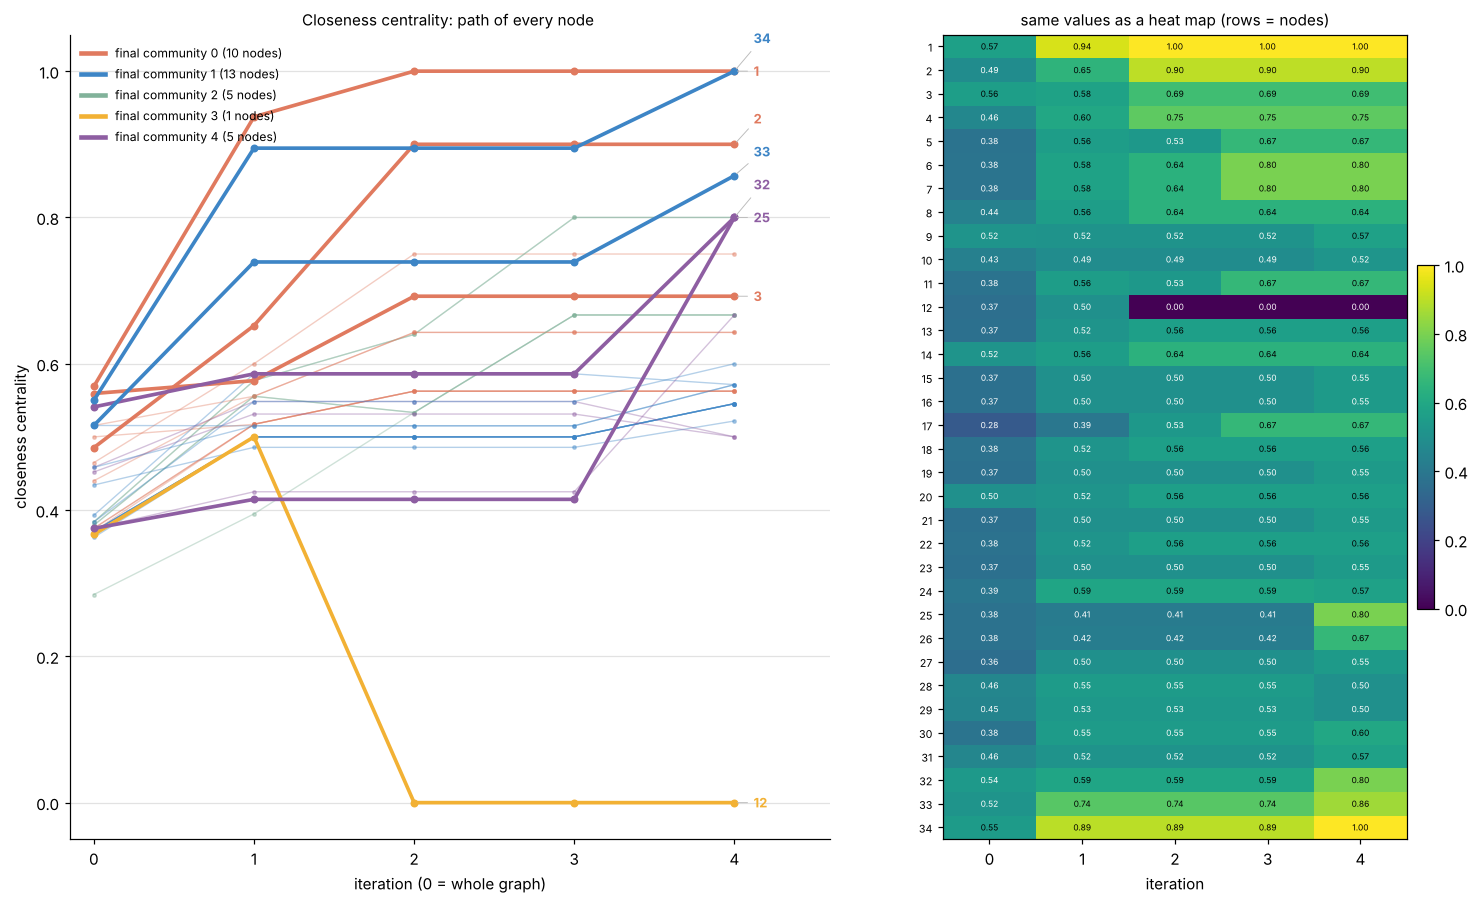

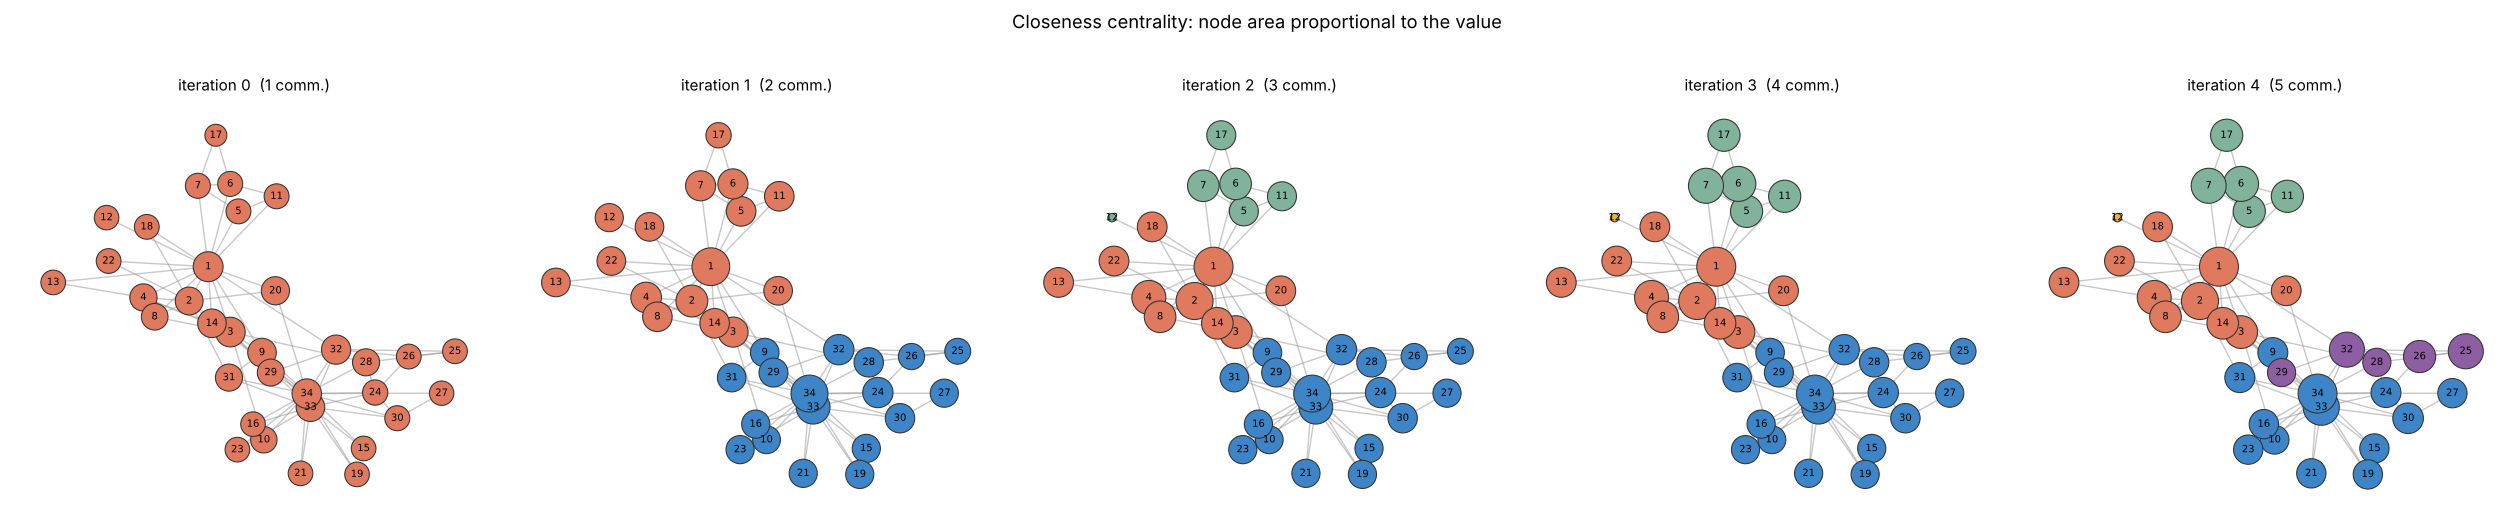

In [17]:
evolution_figure("closeness", tab_h["closeness"], snaps)
size_strip("closeness", tab_h["closeness"], snaps)

**Reading the evolution of closeness centrality**

* **Average:** 0.4265 → 0.5558 → 0.5749 → 0.5961 → 0.6385. Distances inside small, dense groups are short, so closeness mostly rises.
* **Iteration 1:** 33 nodes rise. Node 1 goes 0.569 → 0.938 (+0.369) and node 34 0.550 → 0.895. Node 9 shows a negligible dip (0.516 → 0.515).
* **Iteration 2:** node 12 collapses from 0.500 to 0 (−0.500): inside $\{5,6,7,11,12,17\}$ it has no neighbour, so the community is disconnected and the Wasserman–Faust factor sends it to 0. Nodes 5 and 11 also dip slightly (0.556 → 0.533) for the same reason. Node 2 gains most (+0.248, reaching 0.900).
* **Iteration 3:** when node 12 is removed from that group the remaining five nodes recover (node 5: 0.533 → 0.667; nodes 6, 7: 0.640 → 0.800).
* **Iteration 4:** members of $\{25,26,28,29,32\}$ rise sharply (node 25: +0.385, to 0.800), while nodes 28 and 29 slip a little (e.g. node 28: −0.048).
* **Node 3** gains the least among the hubs (0.559 → 0.692) because it is not a hub of its final community: five of its ten neighbours belong to the other half.

### 17. Clustering coefficient

In [18]:
metric_block("clustering", tab_h["clustering"], snaps)

=== CLUSTERING COEFFICIENT  (handout matrix): value of all 34 nodes at every iteration ===
       it 0   it 1   it 2   it 3   it 4  comm@0  comm@1  comm@2  comm@3  comm@4
node                                                                           
1     0.150  0.187  0.361  0.361  0.361       0       0       0       0       0
2     0.333  0.429  0.429  0.429  0.429       0       0       0       0       0
3     0.244  0.900  0.900  0.900  0.900       0       0       0       0       0
4     0.667  0.667  0.667  0.667  0.667       0       0       0       0       0
5     0.667  0.667  0.000  0.000  0.000       0       0       2       2       2
6     0.500  0.500  0.333  0.333  0.333       0       0       2       2       2
7     0.500  0.500  0.333  0.333  0.333       0       0       2       2       2
8     1.000  1.000  1.000  1.000  1.000       0       0       0       0       0
9     0.500  1.000  1.000  1.000  1.000       0       1       1       1       1
10    0.000  0.000  0.000  0.

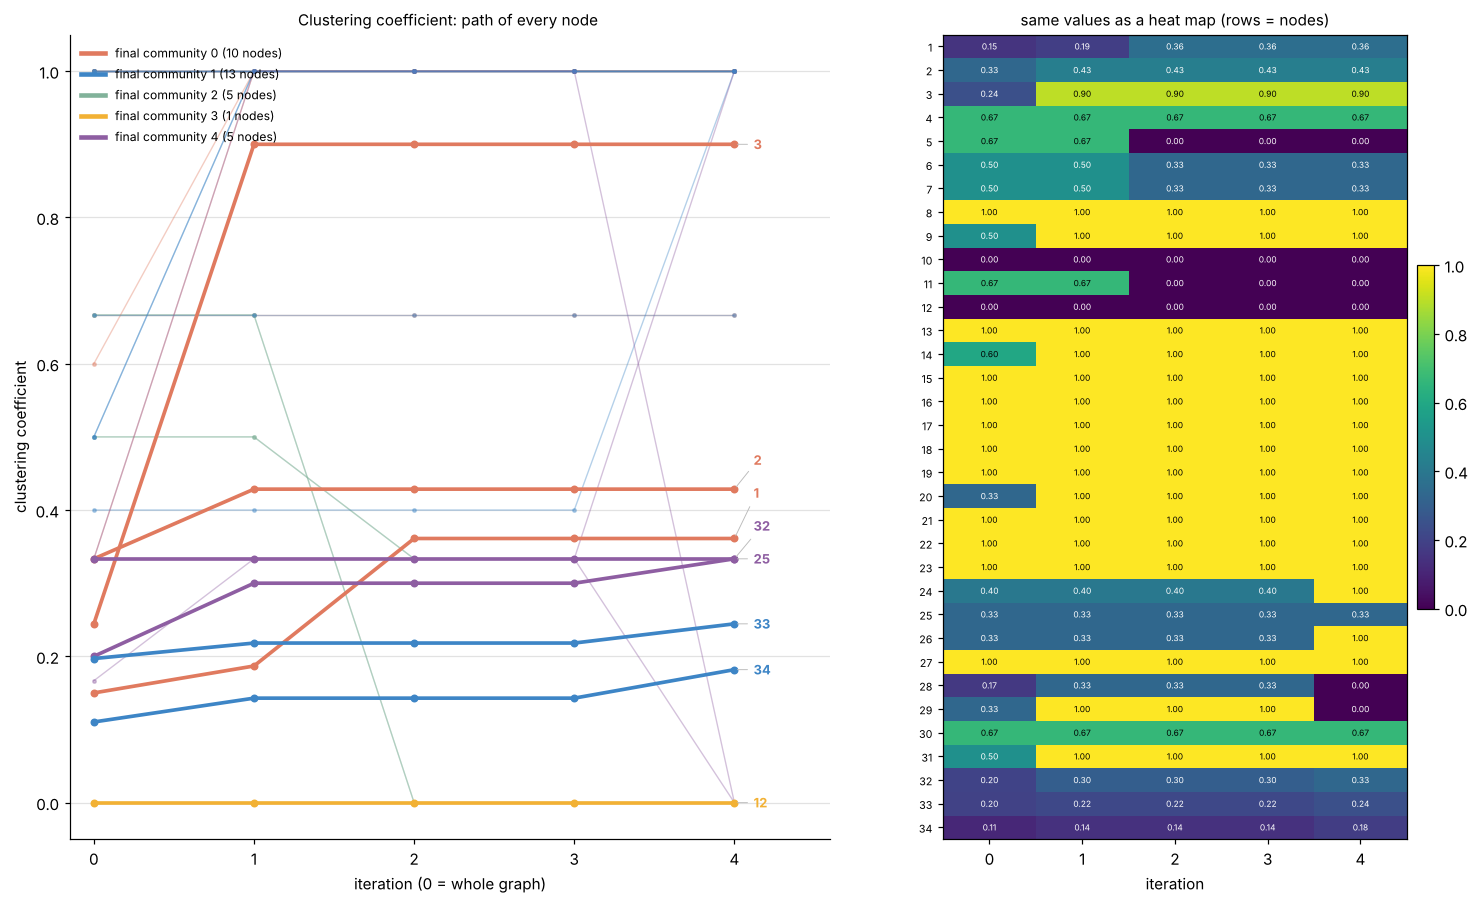

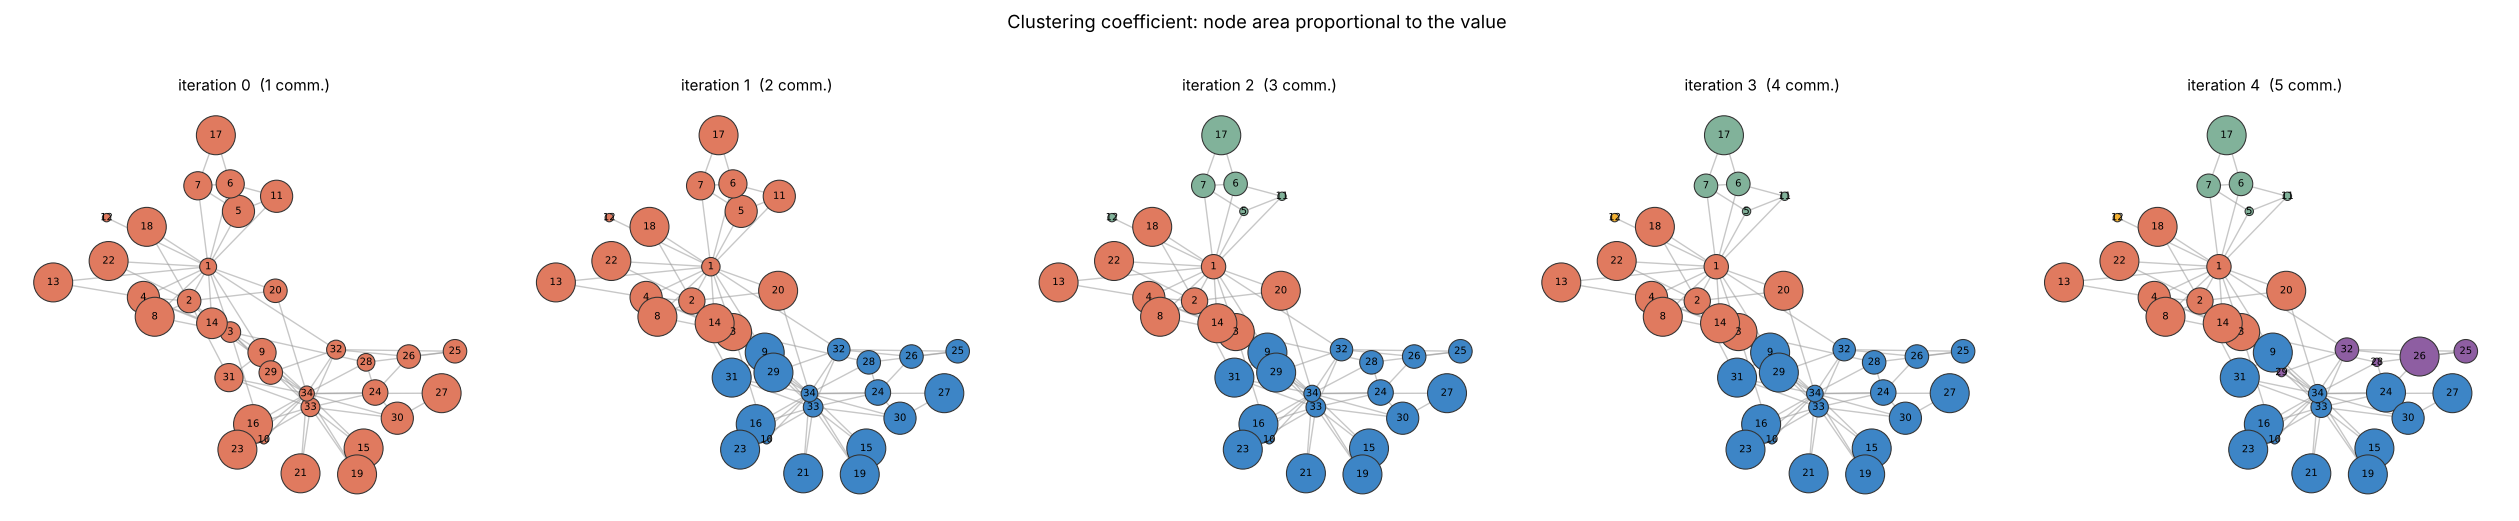

In [19]:
evolution_figure("clustering", tab_h["clustering"], snaps)
size_strip("clustering", tab_h["clustering"], snaps)

**Reading the evolution of the clustering coefficient**

* **Average:** 0.571 → 0.684 → 0.640 → 0.640 → 0.641. It rises once (iteration 1) and then settles — the only metric whose mean does not keep growing.
* **Iteration 1:** 12 nodes rise and none fall; node 20 gains most (+0.667) and node 3 jumps from 0.244 to 0.900: five of its ten neighbours leave, and nine of the ten pairs among the other five are linked.
* **Iteration 2:** one node rises (node 1, to 0.361) and four fall. Node 5 and node 11 drop from 0.667 to 0 because their remaining neighbours (7 and 11, respectively 5 and 6) are not linked to each other.
* **Iteration 3:** nothing changes at all, because node 12 had no clustering to lose (its only neighbour had already gone).
* **Iteration 4:** five nodes rise (node 26: +0.667; node 24: +0.600) and two fall (node 29: −1.0, since only node 32 remains as its neighbour; node 28: −0.333).
* **Counts:** nodes with coefficient 1 go from 11 to 17, nodes with coefficient 0 from 2 to 6. The hubs begin low (node 1: 0.150, node 34: 0.110) because their many neighbours seldom know each other, and they gain within their communities (node 1: 0.361, node 34: 0.182).

## 18. Evolution at a glance

The averages of the four metrics over all 34 nodes, together with $Q$ and the number of communities at each iteration, give a compact picture of the whole run.

average over the 34 nodes at every iteration (handout matrix):
           degree  betweenness  closeness  clustering       Q  communities
iteration                                                                 
0          0.1390       0.0440     0.4265      0.5706  0.0000            1
1          0.2505       0.0568     0.5558      0.6836  0.3715            2
2          0.3355       0.0602     0.5749      0.6397  0.3898            3
3          0.3531       0.0680     0.5961      0.6397  0.3911            4
4          0.4232       0.0919     0.6385      0.6407  0.4094            5


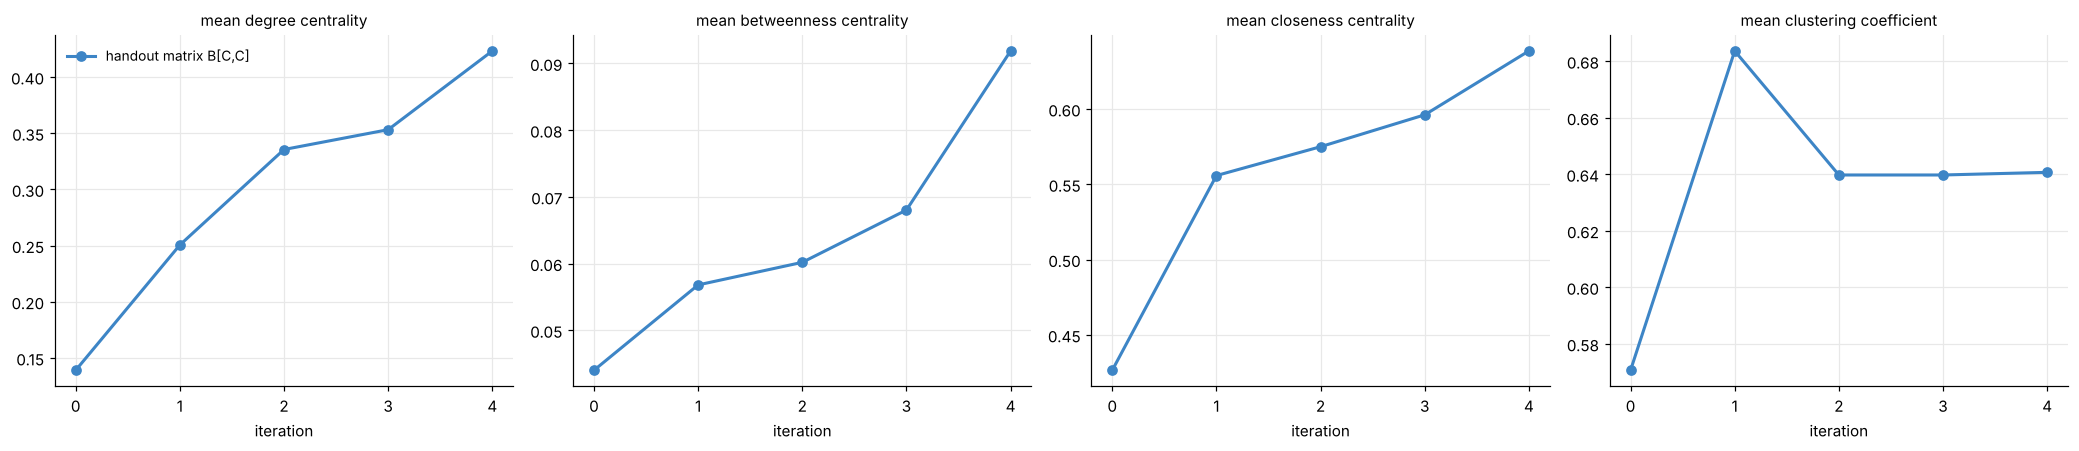

In [20]:
def mean_curves(tabs, snaps_list, labels, colors):
    fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
    for ax, name in zip(axes, METRICS):
        for tb, lab, col in zip(tabs, labels, colors):
            ax.plot(tb[name].columns, tb[name].mean().values, marker="o", color=col, lw=2, label=lab)
        ax.set_title(f"mean {METRIC_LABEL[name]}", fontsize=10)
        ax.set_xlabel("iteration")
        ax.set_xticks(range(max(len(s) for s in snaps_list)))
        ax.grid(color="#e8e8e8"); ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    axes[0].legend(frameon=False, fontsize=9)
    plt.tight_layout()
    plt.show()

mean_tbl = pd.DataFrame({name: tab_h[name].mean() for name in METRICS}).round(4)
mean_tbl["Q"] = [round(x["Q"], 4) if abs(x["Q"]) > 1e-12 else 0.0 for x in snaps]
mean_tbl["communities"] = [len(x["parts"]) for x in snaps]
mean_tbl.index.name = "iteration"
print("average over the 34 nodes at every iteration (handout matrix):")
print(mean_tbl.to_string())

mean_curves([tab_h], [snaps], ["handout matrix B[C,C]"], ["#3d85c6"])

## 19. Complete metric table: all 34 nodes

Table **A** compares each node's value in the whole graph (`full`, iteration 0) with its value in its final community (`final`). Table **B** lists every metric at every iteration for all 34 nodes. Table B is also saved as `karate_metric_evolution_handout.csv`.

In [21]:
full_vs_final = pd.concat(
    {name: pd.DataFrame({"full": tab_h[name][0], "final": tab_h[name][last_step]}) for name in METRICS}, axis=1)
full_vs_final.insert(0, ("", "community"), final_label)

assert full_vs_final.shape[0] == 34
print("A) iteration 0 (whole graph) versus final community, all 34 nodes")
print(full_vs_final.round(3).to_string())

master = pd.concat({name: tab_h[name] for name in METRICS}, axis=1)
master.insert(0, ("", "final community"), final_label)
print("\nB) every metric at every iteration, all 34 nodes")
print(master.round(3).to_string())

master.round(6).to_csv("/mnt/user-data/outputs/karate_metric_evolution_handout.csv")
print("\n(table B also written to karate_metric_evolution_handout.csv)")

shift = (tab_h["degree"][last_step] - tab_h["degree"][0]).sort_values()
print("\nchange in degree centrality (final minus full graph):")
print("  five largest increases:", shift.tail(5).round(3).to_dict())
print("  nodes with a decrease :", shift[shift < 0].round(3).to_dict())

A) iteration 0 (whole graph) versus final community, all 34 nodes
               degree        betweenness        closeness        clustering       
     community   full  final        full  final      full  final       full  final
node                                                                              
1            0  0.485  1.000       0.438  0.354     0.569  1.000      0.150  0.361
2            0  0.273  0.889       0.054  0.215     0.485  0.900      0.333  0.429
3            0  0.303  0.556       0.144  0.007     0.559  0.692      0.244  0.900
4            0  0.182  0.667       0.012  0.062     0.465  0.750      0.667  0.667
5            2  0.091  0.500       0.001  0.083     0.379  0.667      0.667  0.000
6            2  0.121  0.750       0.030  0.250     0.384  0.800      0.500  0.333
7            2  0.121  0.750       0.030  0.250     0.384  0.800      0.500  0.333
8            0  0.121  0.444       0.000  0.000     0.440  0.643      1.000  1.000
9            1  0.152

## 20. Detected communities versus the real factions

Only now is the `club` attribute read; it played no role in the matrices, eigenvectors, sign rule or recursion.

The detected communities and the real camps are different objects. The procedure raises modularity and was never asked to reproduce the camps, so an exact match should not be expected. As a single score the adjusted Rand index (ARI), computed from pair counts, is used: $1$ for identical groupings, around $0$ for chance-level agreement.

In [22]:
club = pd.Series({v: G.nodes[v]["club"] for v in nodes})

def adjusted_rand(l1, l2):
    t = pd.crosstab(pd.Series(l1), pd.Series(l2)).values
    cells = sum(comb(int(x), 2) for x in t.ravel())
    rows = sum(comb(int(x), 2) for x in t.sum(axis=1))
    cols = sum(comb(int(x), 2) for x in t.sum(axis=0))
    expected = rows * cols / comb(int(t.sum()), 2)
    return (cells - expected) / (0.5 * (rows + cols) - expected)

def compare_with_camps(snaps, label):
    fin = community_at(snaps, snaps[-1]["step"])
    print(f"[{label}] final communities against the real camps:")
    print(pd.crosstab(fin.rename("community"), club.rename("camp")).to_string())
    print()
    for cid, g in snaps[-1]["parts"].items():
        print(f"  community {cid}: {g}")
    print()
    for step in (1, snaps[-1]["step"]):
        lab = community_at(snaps, step)
        print(f"  ARI against the real camps after iteration {step} ({len(snaps[step]['parts'])} communities): "
              f"{adjusted_rand(lab.values, club.values):.3f}")

compare_with_camps(snaps, "handout")

first = snaps[1]["parts"]
majority = {cid: club[g].value_counts().idxmax() for cid, g in first.items()}
off_side = sorted(v for cid, g in first.items() for v in g if club[v] != majority[cid])
print(f"\nfirst split: community 0 is mostly '{majority[0]}', community 1 is mostly '{majority[1]}'")
print("nodes on the 'wrong' side of the first split:", off_side)

[handout] final communities against the real camps:
camp       Mr. Hi  Officer
community                 
0              10        0
1               1       12
2               5        0
3               1        0
4               0        5

  community 0: [1, 2, 3, 4, 8, 13, 14, 18, 20, 22]
  community 1: [9, 10, 15, 16, 19, 21, 23, 24, 27, 30, 31, 33, 34]
  community 2: [5, 6, 7, 11, 17]
  community 3: [12]
  community 4: [25, 26, 28, 29, 32]

  ARI against the real camps after iteration 1 (2 communities): 0.882
  ARI against the real camps after iteration 4 (5 communities): 0.446

first split: community 0 is mostly 'Mr. Hi', community 1 is mostly 'Officer'
nodes on the 'wrong' side of the first split: [9]


## 21. Newman's correction

### 21.1 Why the correction is needed

Dividing a community $g$ changes modularity by
$$
\Delta Q=\frac1{4m}\Big[\sum_{i,j\in g}B_{ij}s_is_j-\sum_{i,j\in g}B_{ij}\Big].
$$
The second sum is not zero for a *sub*-community (it vanishes only for the whole graph, where all rows of $B$ sum to zero). Using $s_i^2=1$, it can be written $\sum_{i,j}\delta_{ij}s_is_j\sum_{k\in g}B_{ik}$, which gives
$$
\Delta Q=\frac1{4m}\,s^\top B^{(g)}s,\qquad B^{(g)}_{ij}=B_{ij}-\delta_{ij}\sum_{k\in g}B_{ik}.
$$
Two consequences:

* every row of $B^{(g)}$ sums to zero, so the all-ones vector is an eigenvector with eigenvalue 0; hence if the leading eigenvalue is $\le0$ the community is genuinely indivisible, and if it is positive the leading eigenvector is orthogonal to $\mathbf 1$ and must contain both signs (no degenerate cuts);
* the uncorrected block $B[C,C]$ **over-states** the gain by exactly $\frac1{4m}\sum_{i,j\in C}B_{ij}$.

The cell below shows the effect on the 16-node community produced by the first cut.

In [23]:
# how the correction changes the block matrix of the first non-trivial community (iteration 1, community 0)
members = snaps[1]["parts"][0]
Bc_plain = split_block(members, newman=False)
Bc_corr  = split_block(members, newman=True)
diag_term = Bc_plain.sum(axis=1)

demo = pd.DataFrame({"node": members, "B_ii (handout diagonal)": np.diag(Bc_plain),
                     "row sum of B[C,C]": diag_term, "diagonal after correction": np.diag(Bc_corr)}).set_index("node")
print(f"community of iteration 1 with {len(members)} nodes")
print(demo.round(3).to_string())
print("\nmax |row sum| of B[C,C]            :", np.abs(Bc_plain.sum(axis=1)).max().round(4))
print("max |row sum| after the correction :", np.abs(Bc_corr.sum(axis=1)).max().round(12))
print("1^T M 1 with the handout block      :", float(np.ones(len(members)) @ Bc_plain @ np.ones(len(members))).__round__(4))
print("1^T M 1 with the corrected block    :", float(np.ones(len(members)) @ Bc_corr @ np.ones(len(members))).__round__(12))

community of iteration 1 with 16 nodes
      B_ii (handout diagonal)  row sum of B[C,C]  diagonal after correction
node                                                                       
1                      -1.641              6.205                     -7.846
2                      -0.519              3.615                     -4.135
3                      -0.641              0.128                     -0.769
4                      -0.231              3.077                     -3.308
5                      -0.058              1.538                     -1.596
6                      -0.103              2.051                     -2.154
7                      -0.103              2.051                     -2.154
8                      -0.103              2.051                     -2.154
11                     -0.058              1.538                     -1.596
12                     -0.006              0.513                     -0.519
13                     -0.026              1.026 

### 21.2 Running the procedure with the correction

Same code as Section 9 with `newman=True`. Because the corrected formula is exact, the function also refuses a sign cut whose $\Delta Q$ is not positive. (The leading eigenvalue can be positive while the sign-rounded cut still loses modularity, since the relaxation is only approximate.)

In [24]:
snaps_n, tries_n = recursive_split(newman=True)      # Newman's generalised matrix
show_log(tries_n)
print()
show_summary(snaps_n)
Q_newman = verify_run(snaps_n, tries_n, must_increase=False)
last_step_n = snaps_n[-1]["step"]
final_parts_n = snaps_n[-1]["parts"]
print(f"\nAccepted cuts: {last_step_n}; final communities: {len(final_parts_n)}; final Q = {Q_newman[-1]:.4f}")

# with Newman's matrix the formula value IS the true change in Q
for r in tries_n:
    if r["step"] is not None:
        true = snaps_n[r["step"]]["Q"] - snaps_n[r["step"] - 1]["Q"]
        assert np.isclose(true, r["dQ_formula"]), "Newman's Delta Q must equal the true change"
print("check passed: for Newman's matrix the formula equals the true change in Q at every accepted cut")

 try step  community  size  lambda_1  dQ_formula children (sizes)                               outcome
   1    1          0    34    4.9771      0.3715          16 + 18                        split accepted
   2    2          0    16    1.1785      0.0012            7 + 9                        split accepted
   3    -          0     7   -0.0000           -                  stop: leading eigenvalue not positive
   4    -          2     9    0.0602     -0.0158                       stop: sign cut would not raise Q
   5    3          1    18    0.8594      0.0207           12 + 6                        split accepted
   6    -          1    12   -0.0000           -                  stop: leading eigenvalue not positive
   7    -          3     6    0.0000           -                  stop: leading eigenvalue not positive

Accepted cuts:
  step 1: community 0 (size 34)
      keeps id 0: [1, 2, 3, 4, 5, 6, 7, 8, 11, 12, 13, 14, 17, 18, 20, 22]
      new id   1: [9, 10, 15, 16, 19, 21, 23,

### 21.3 Formula value versus true change in $Q$, and modularity along the run

The left panel plots $Q$ after every accepted cut for the two variants; the right panel compares, for each accepted cut, what the formula claims with what $Q$ really gains.

handout matrix B[C,C]  -- formula value versus the true change of Q
           cut community  size  formula Delta Q  sum of B over community / 4m  true change in Q
iteration                                                                                      
1                      0    34           0.3715                       -0.0000            0.3715
2                      0    16           0.1112                        0.0929            0.0183
3                      2     6           0.0338                        0.0325            0.0013
4                      1    18           0.1112                        0.0929            0.0183

Newman's generalised matrix  -- formula value versus the true change of Q
           cut community  size  formula Delta Q  true change in Q
iteration                                                        
1                      0    34           0.3715            0.3715
2                      0    16           0.0012            0.0012
3                

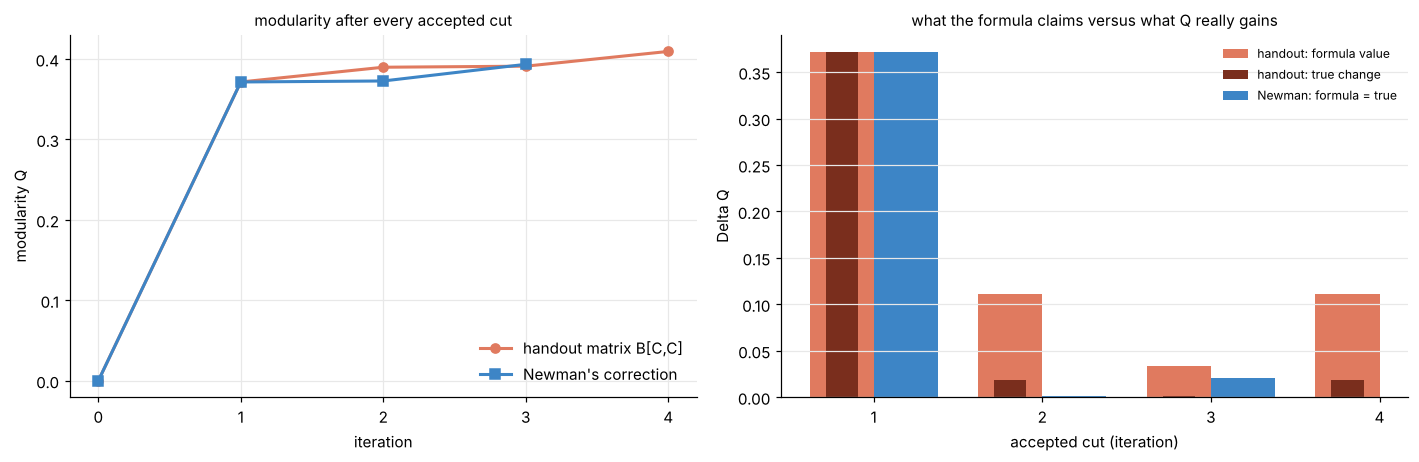

In [25]:
def dq_table(snaps_x, tries_x, with_gap=True):
    rows = []
    for r in tries_x:
        if r["step"] is not None:
            s = r["step"]
            parent = snaps_x[s - 1]["parts"][r["community"]]
            overshoot = sub_block(B, parent).sum() / (4 * M)           # the term the handout matrix leaves out
            rows.append((s, r["community"], r["size"], round(r["dQ_formula"], 4), round(overshoot, 4),
                         round(snaps_x[s]["Q"] - snaps_x[s - 1]["Q"], 4)))
    out = pd.DataFrame(rows, columns=["iteration", "cut community", "size", "formula Delta Q",
                                      "sum of B over community / 4m", "true change in Q"]).set_index("iteration")
    return out if with_gap else out.drop(columns="sum of B over community / 4m")

print("handout matrix B[C,C]  -- formula value versus the true change of Q")
print(dq_table(snaps, tries).to_string())
print("\nNewman's generalised matrix  -- formula value versus the true change of Q")
print(dq_table(snaps_n, tries_n, with_gap=False).to_string())

hd = dq_table(snaps, tries)
assert np.allclose(hd["formula Delta Q"] - hd["sum of B over community / 4m"], hd["true change in Q"], atol=1e-4)
print("\ncheck passed: handout formula minus (sum of B over the community / 4m) equals the true change in Q at every cut")

# the 10 + 6 cut that the handout run made inside the 16-node community, scored with Newman's exact formula
parent16 = snaps[1]["parts"][0]
alt_plus = snaps[2]["parts"][0]
s_alt = np.array([1 if v in alt_plus else -1 for v in parent16])
print("exact Delta Q of the handout's 10 + 6 cut of the 16-node community :", round(float(s_alt @ split_block(parent16, True) @ s_alt / (4 * M)), 4))
tn = [r for r in tries_n if r["community"] == 0 and r["size"] == 16][0]
print("exact Delta Q of the cut that Newman's sign rule chose (7 + 9)      :", round(tn["dQ_formula"], 4))

rejected = [r for r in tries_n if r["outcome"].startswith("stop: sign cut")]
print("\ncuts that Newman's test refused because they would lower Q:")
for r in rejected:
    print(f"  community {r['community']} (size {r['size']}): lambda_1 = {r['lambda_1']:.4f}, formula Delta Q = {r['dQ_formula']:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
ax.plot(range(len(snaps)), [max(x["Q"], 0) for x in snaps], "o-", color="#e07a5f", lw=2, label="handout matrix B[C,C]")
ax.plot(range(len(snaps_n)), [max(x["Q"], 0) for x in snaps_n], "s-", color="#3d85c6", lw=2, label="Newman's correction")
ax.set_xlabel("iteration"); ax.set_ylabel("modularity Q"); ax.set_title("modularity after every accepted cut", fontsize=10)
ax.set_xticks(range(max(len(snaps), len(snaps_n)))); ax.legend(frameon=False); ax.grid(color="#e8e8e8")
ax = axes[1]
w = 0.38
xs = np.arange(1, last_step + 1)
ax.bar(xs - w/2, [next(r["dQ_formula"] for r in tries if r["step"] == s) for s in xs], w, color="#e07a5f", label="handout: formula value")
ax.bar(xs - w/2, [snaps[s]["Q"] - snaps[s-1]["Q"] for s in xs], w * 0.5, color="#7a2e1d", label="handout: true change")
xn = np.arange(1, last_step_n + 1)
ax.bar(xn + w/2, [next(r["dQ_formula"] for r in tries_n if r["step"] == s) for s in xn], w, color="#3d85c6", label="Newman: formula = true")
ax.set_xlabel("accepted cut (iteration)"); ax.set_ylabel("Delta Q"); ax.set_title("what the formula claims versus what Q really gains", fontsize=10)
ax.set_xticks(range(1, max(last_step, last_step_n) + 1)); ax.legend(frameon=False, fontsize=8); ax.grid(axis="y", color="#e8e8e8")
for a in axes:
    for side in ("top", "right"):
        a.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

### 21.4 The network after every accepted cut (Newman's correction)

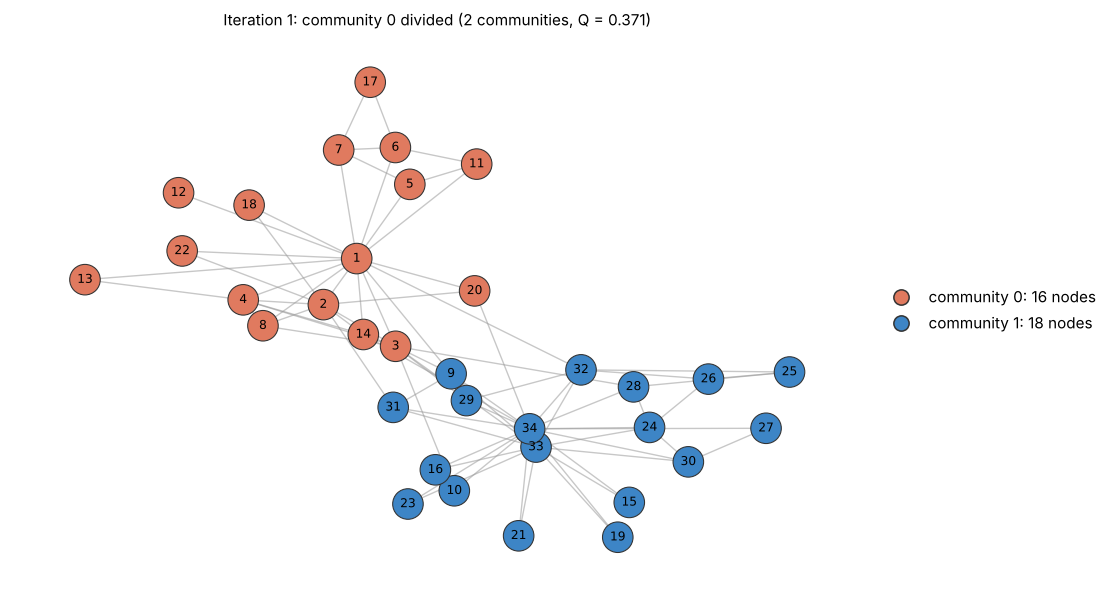

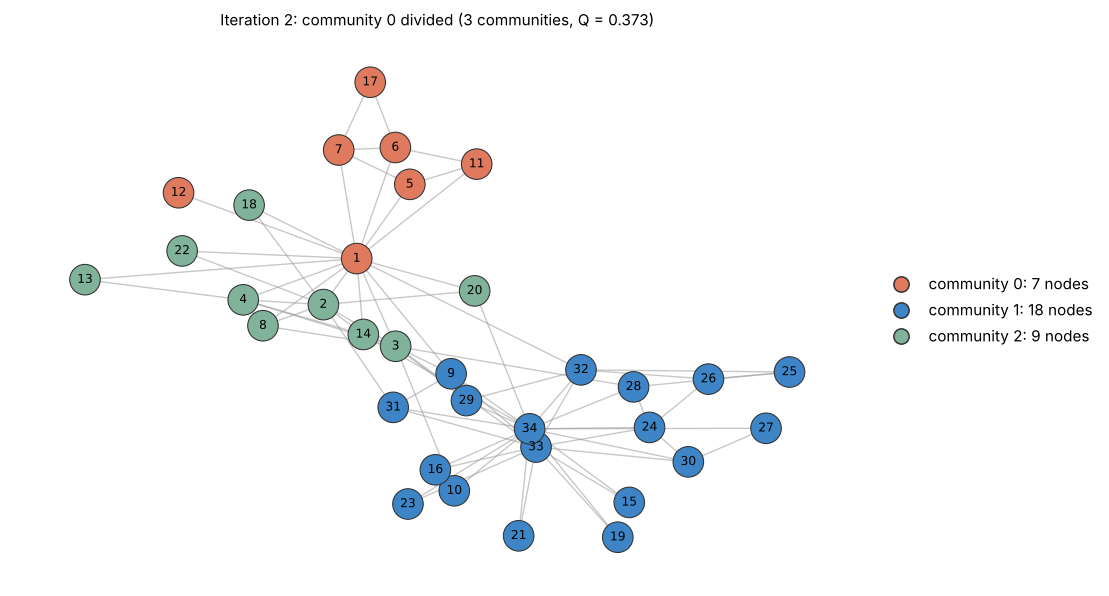

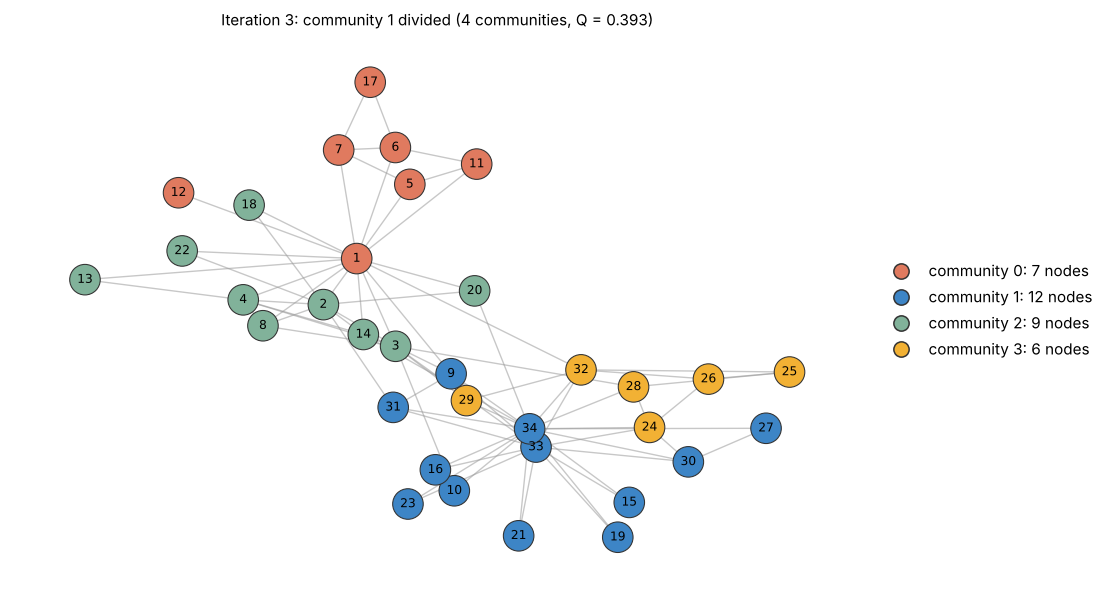

In [26]:
draw_all_cuts(snaps_n, tries_n)

### 21.5 Evolution of the four metrics under Newman's correction

For each metric: the complete 34-node table, the per-iteration summary and the step-to-step movement, exactly as in Sections 14–17 (all tables are also saved as `karate_metric_evolution_newman.csv`). Then the four line plots and the node-area pictures.

In [27]:
long_n, tab_n, broken_n = collect_history(snaps_n)
print("disconnected induced communities (step, id):", broken_n or "none")
final_label_n = community_at(snaps_n, last_step_n)

for name in METRICS:
    print(f"=== {METRIC_LABEL[name].upper()} (Newman's correction): all 34 nodes at every iteration ===")
    print(evolution_table(name, tab_n[name], snaps_n).round(3).to_string())
    d, mv = evolution_digest(name, tab_n[name], snaps_n)
    print("\nsummary per iteration:")
    print(d.to_string())
    print("\nstep-to-step movement:")
    print(mv.to_string())
    print()

master_n = pd.concat({name: tab_n[name] for name in METRICS}, axis=1)
master_n.insert(0, ("", "final community"), final_label_n)
master_n.round(6).to_csv("/mnt/user-data/outputs/karate_metric_evolution_newman.csv")
print("(complete tables written to karate_metric_evolution_newman.csv)")

disconnected induced communities (step, id): none
=== DEGREE CENTRALITY (Newman's correction): all 34 nodes at every iteration ===
       it 0   it 1   it 2   it 3  comm@0  comm@1  comm@2  comm@3
node                                                            
1     0.485  0.933  0.833  0.833       0       0       0       0
2     0.273  0.533  0.875  0.875       0       0       2       2
3     0.303  0.333  0.500  0.500       0       0       2       2
4     0.182  0.400  0.625  0.625       0       0       2       2
5     0.091  0.200  0.500  0.500       0       0       0       0
6     0.121  0.267  0.667  0.667       0       0       0       0
7     0.121  0.267  0.667  0.667       0       0       0       0
8     0.121  0.267  0.375  0.375       0       0       2       2
9     0.152  0.176  0.176  0.273       0       1       1       1
10    0.061  0.059  0.059  0.091       0       1       1       1
11    0.091  0.200  0.500  0.500       0       0       0       0
12    0.030  0.067  0.16

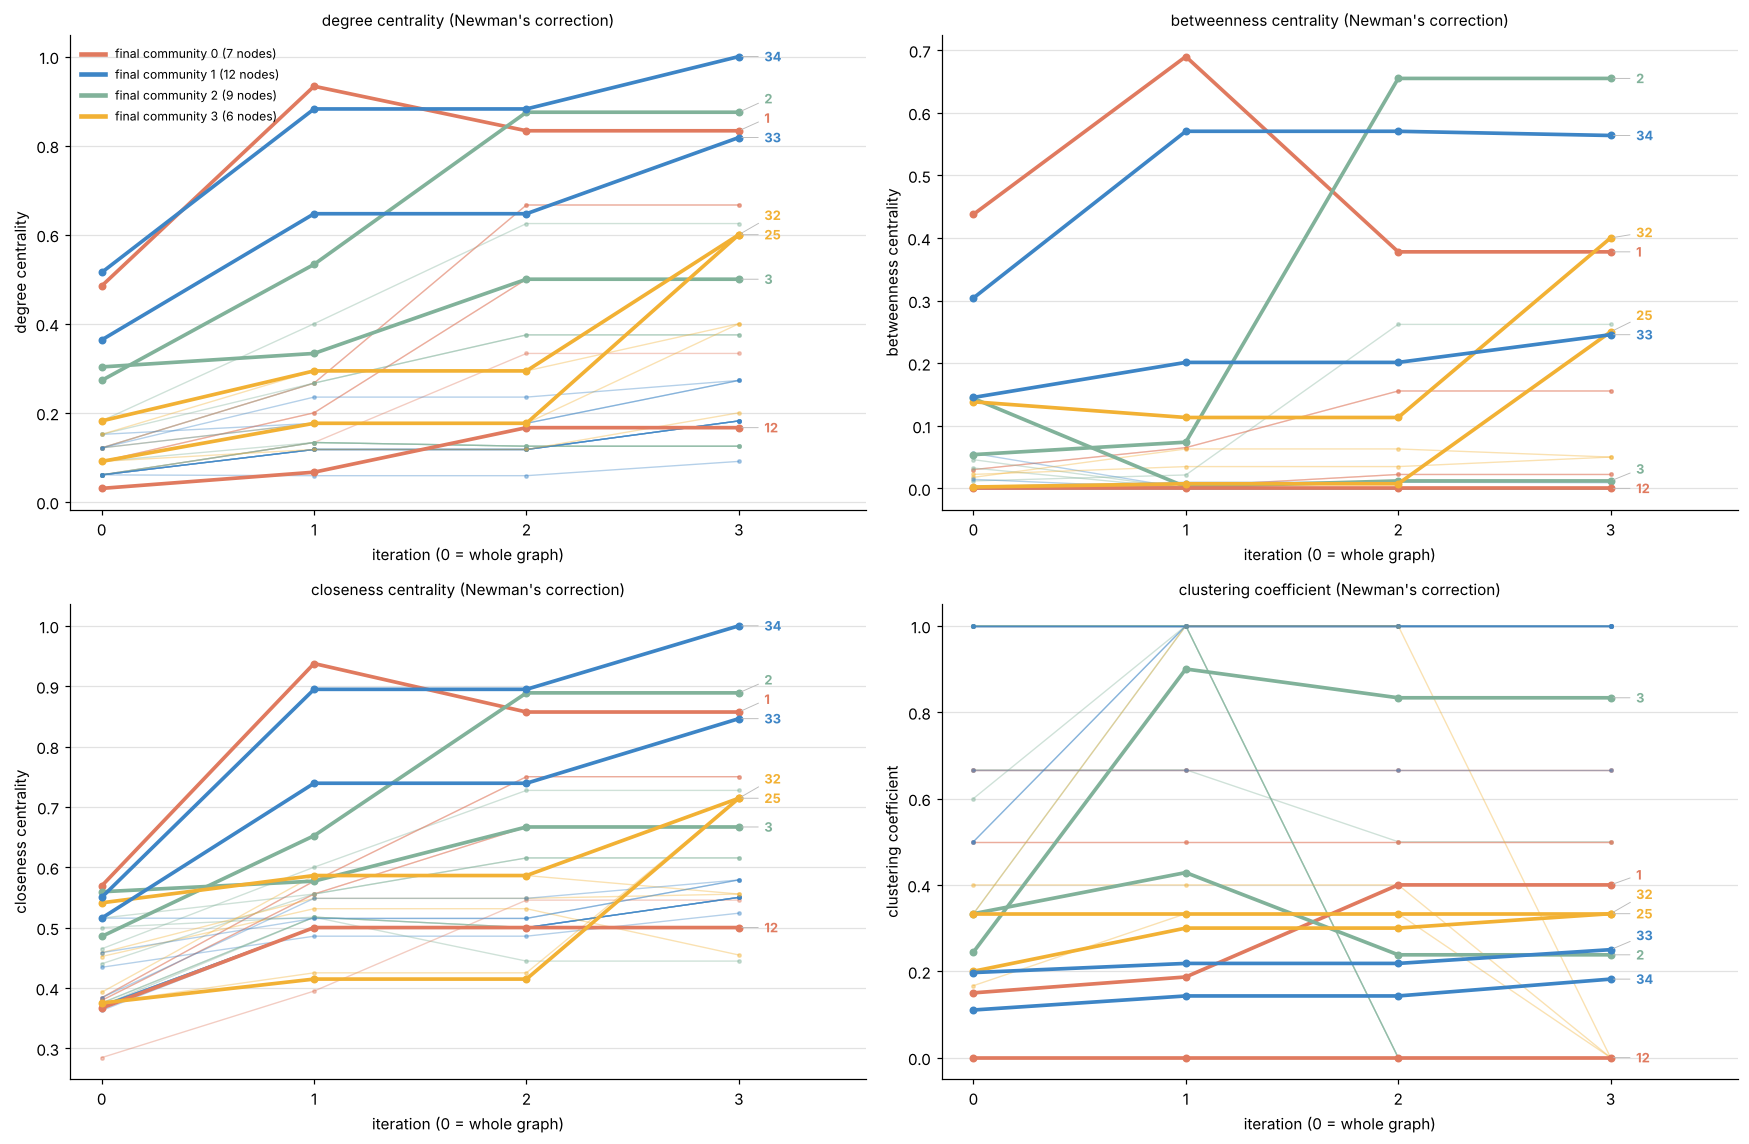

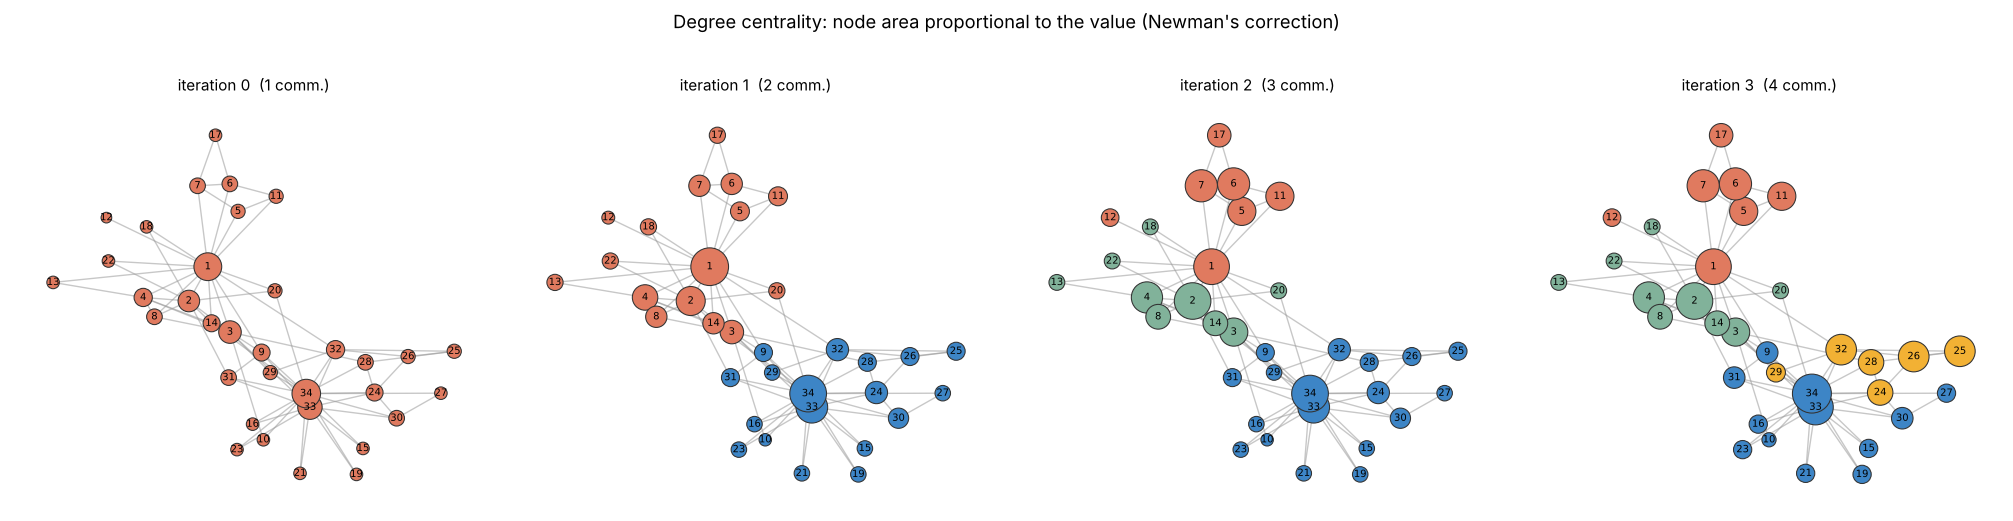

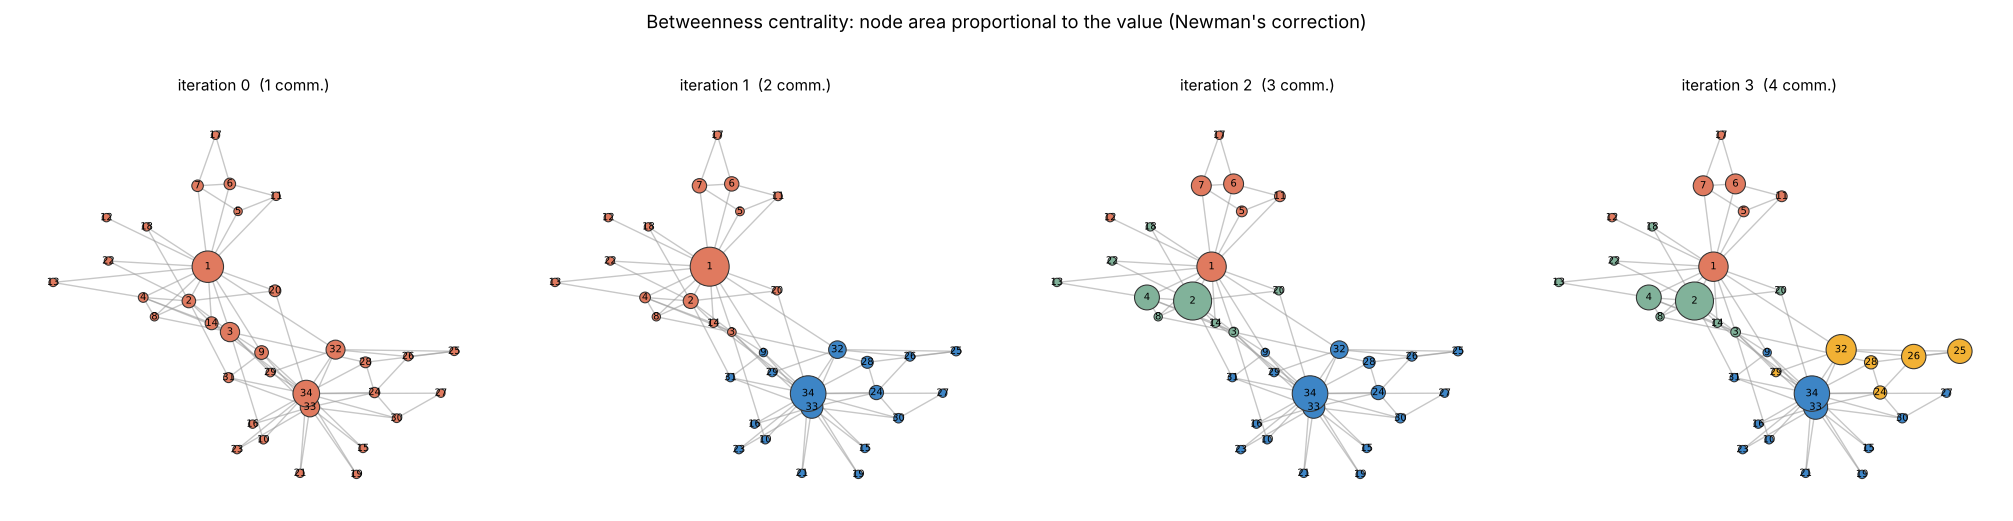

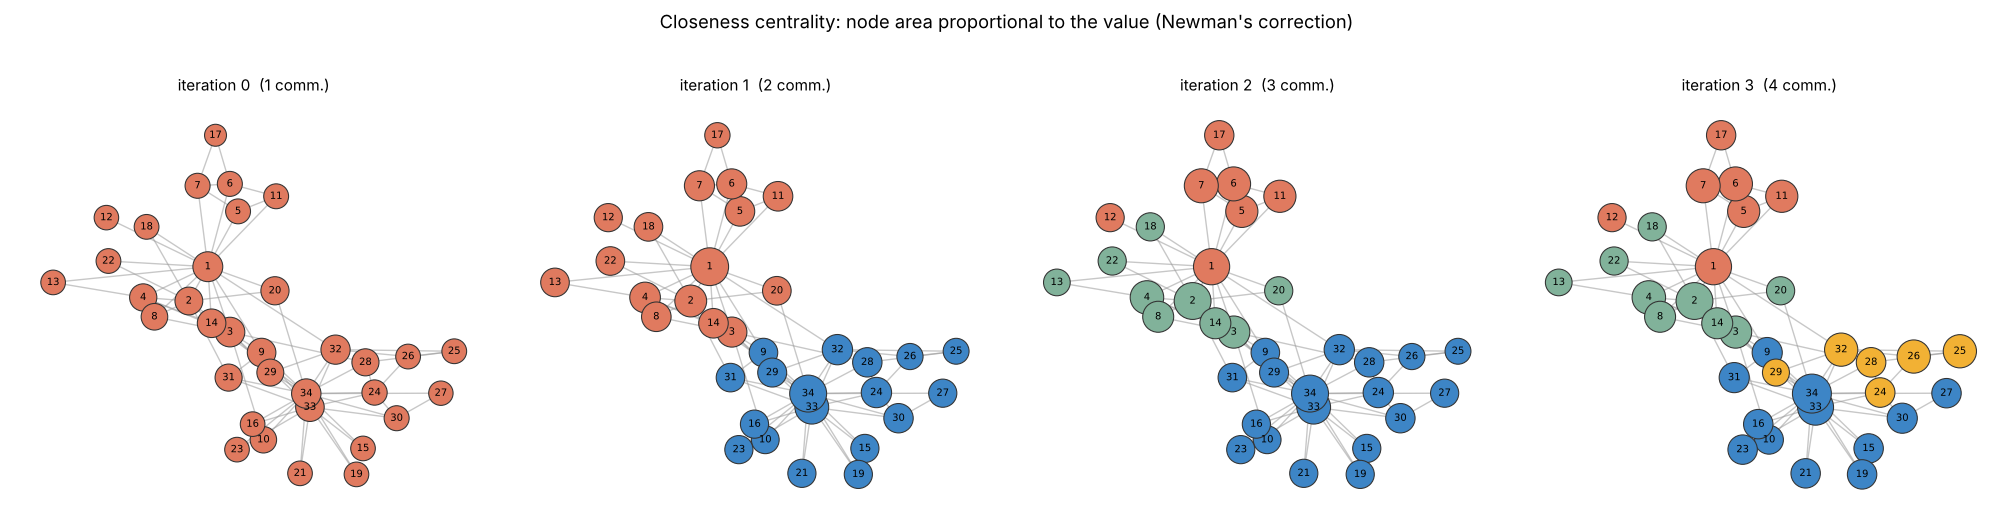

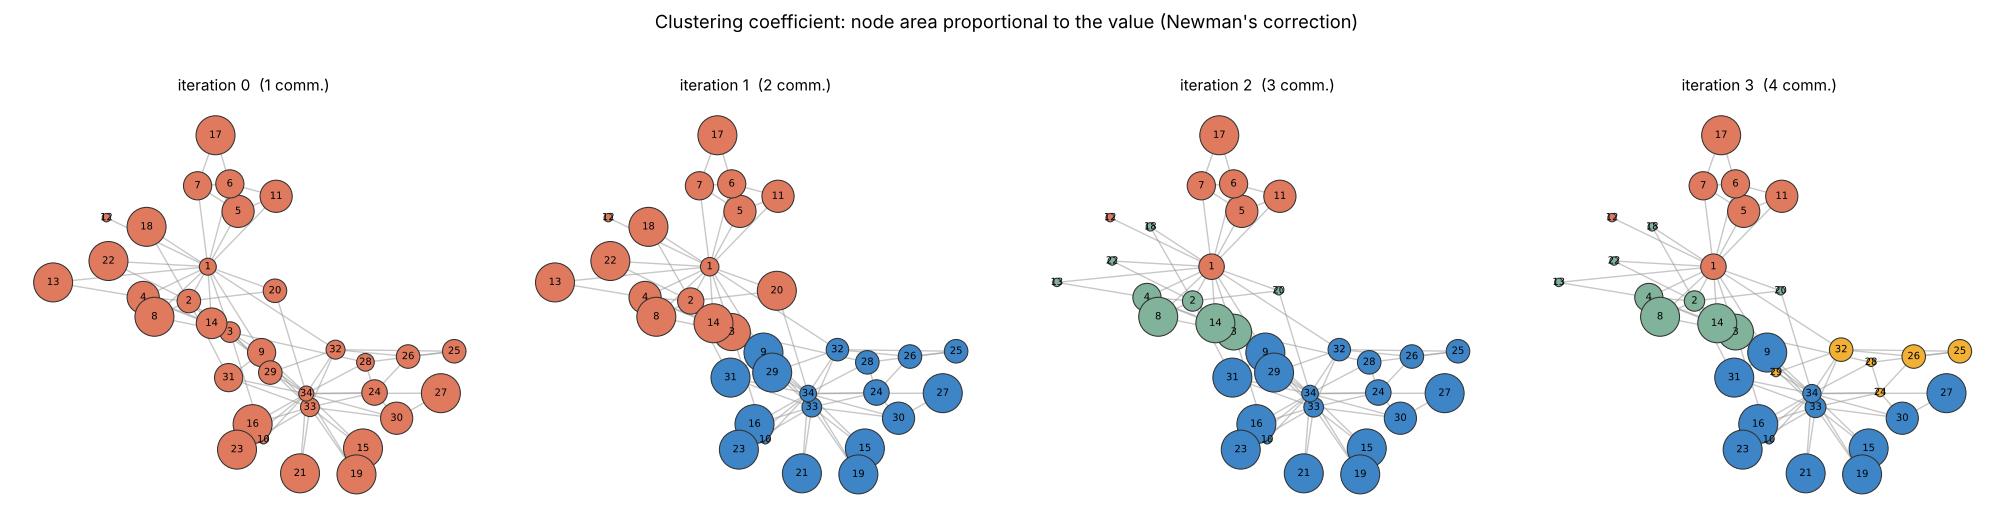

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10.5))
for ax, name in zip(axes.ravel(), METRICS):
    lines_panel(ax, tab_n[name], METRIC_LABEL[name], snaps_n, title=f"{METRIC_LABEL[name]} (Newman's correction)",
                legend=(name == "degree"))
plt.tight_layout()
plt.show()

for name in METRICS:
    size_strip(name, tab_n[name], snaps_n, tag="(Newman's correction)")

**Short reading of the corrected run** (full interpretation in Section 22)

* **Degree:** the average rises 0.139 → 0.251 → 0.325 → 0.398; node 1 *falls* from 0.933 to 0.833 at iteration 2 (it is no longer linked to every member of its group), and node 34 reaches 1.0 at iteration 3.
* **Betweenness:** node 2 jumps from 0.074 to 0.655 at iteration 2 and becomes the top broker, while node 1 drops from 0.690 to 0.378.
* **Closeness:** the average rises 0.4265 → 0.5558 → 0.5878 → 0.6267; no node ends below its starting value.
* **Clustering:** the average rises to 0.684 and then *falls* to 0.560 and 0.512; nodes 13, 18 and 22 fall from 1.0 to 0 at iteration 2, since only one of their neighbours is left in their community.

### 21.6 The two variants side by side

Averages of every metric over the 34 nodes for both variants (the curves coincide at iterations 0 and 1, because the first cut is the same), the node-by-node gap of the final values, and the agreement with the real camps.

average over the 34 nodes at every iteration (Newman's correction):
           degree  betweenness  closeness  clustering       Q  communities
iteration                                                                 
0          0.1390       0.0440     0.4265      0.5706  0.0000            1
1          0.2505       0.0568     0.5558      0.6836  0.3715            2
2          0.3245       0.0785     0.5878      0.5598  0.3727            3
3          0.3981       0.1024     0.6267      0.5119  0.3934            4


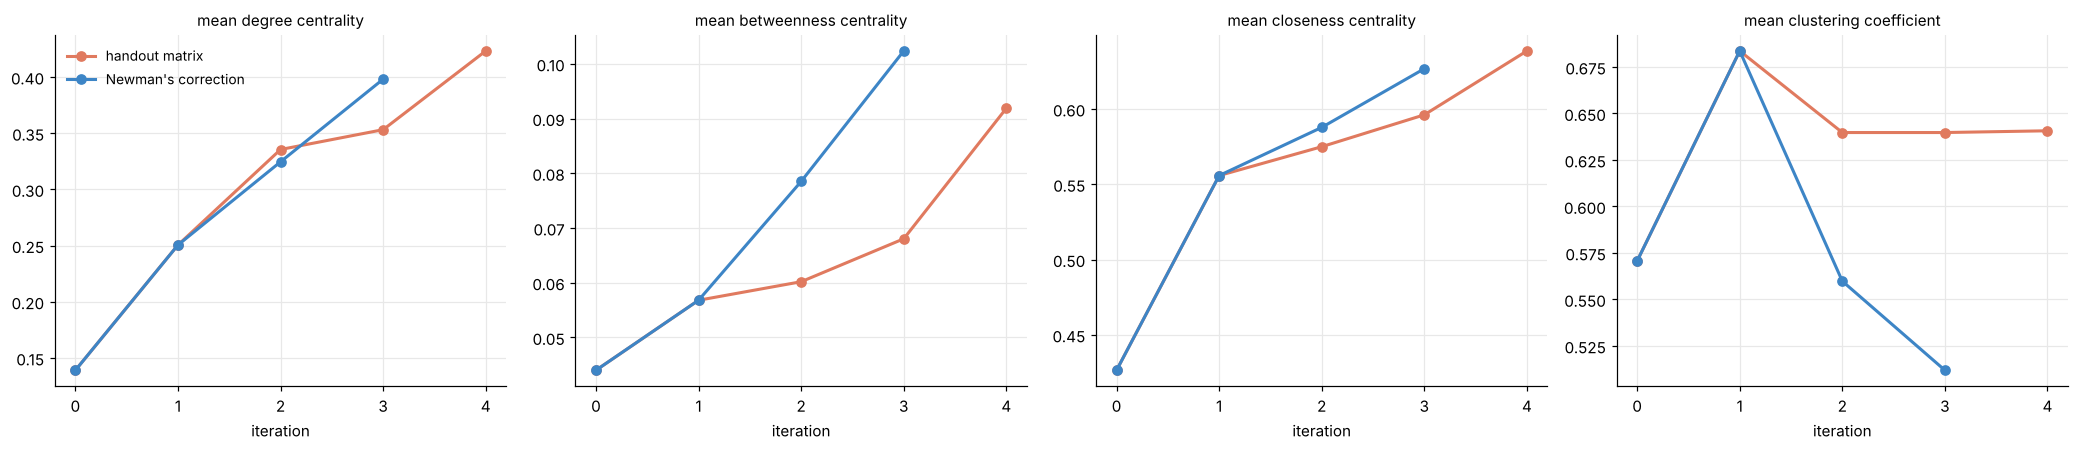


final value under Newman minus final value under the handout matrix, all 34 nodes:
      comm (handout)  comm (Newman)  degree centrality  betweenness centrality  closeness centrality  clustering coefficient
node                                                                                                                        
1                  0              0             -0.167                   0.024                -0.143                   0.039
2                  0              2             -0.014                   0.439                -0.011                  -0.190
3                  0              2             -0.056                   0.005                -0.026                  -0.067
4                  0              2             -0.042                   0.199                -0.023                  -0.167
5                  2              0              0.000                  -0.061                 0.000                   0.667
6                  2              0      

In [29]:
mean_n = pd.DataFrame({name: tab_n[name].mean() for name in METRICS}).round(4)
mean_n["Q"] = [round(x["Q"], 4) if abs(x["Q"]) > 1e-12 else 0.0 for x in snaps_n]
mean_n["communities"] = [len(x["parts"]) for x in snaps_n]
mean_n.index.name = "iteration"
print("average over the 34 nodes at every iteration (Newman's correction):")
print(mean_n.to_string())

mean_curves([tab_h, tab_n], [snaps, snaps_n], ["handout matrix", "Newman's correction"], ["#e07a5f", "#3d85c6"])

# node-by-node gap between the two variants at the end
gap = pd.DataFrame({
    f"{METRIC_LABEL[name]}": tab_n[name][last_step_n] - tab_h[name][last_step] for name in METRICS
}).round(3)
gap.insert(0, "comm (handout)", final_label)
gap.insert(1, "comm (Newman)", final_label_n)
print("\nfinal value under Newman minus final value under the handout matrix, all 34 nodes:")
print(gap.to_string())

compare_with_camps(snaps_n, "Newman")

### Numbers used in the discussion

The cell below prints every figure that the next section quotes, so each statement can be traced to an output.

In [30]:
def lead(tab, step, k=4):
    return tab[step].nlargest(k).round(3).to_dict()

def facts_for(tag, tabs, snaps_x, tries_x):
    fin = snaps_x[-1]["step"]
    print("#" * 8, tag, "#" * 8)
    for name in METRICS:
        print(f"-- {name}: leaders at every iteration")
        for s in tabs[name].columns:
            print(f"   it {s}: {lead(tabs[name], s, 5)}")
    for name in METRICS:
        shift = tabs[name][fin] - tabs[name][0]
        print(f"-- {name}: full -> final")
        print("   rose  :", sorted(shift.index[shift > 1e-6].tolist()))
        print("   fell  :", sorted(shift.index[shift < -1e-6].tolist()))
        print("   same  :", sorted(shift.index[shift.abs() <= 1e-6].tolist()))
        print("   top rises:", shift.nlargest(5).round(3).to_dict())
        print("   top falls:", shift.nsmallest(5).round(3).to_dict())
    print("-- betweenness positive -> exactly 0:", sorted(tabs["betweenness"].index[(tabs["betweenness"][0] > 1e-9) & (tabs["betweenness"][fin] < 1e-9)].tolist()))
    print("-- clustering value 1 :", int((tabs["clustering"][0] > 1-1e-9).sum()), "->", int((tabs["clustering"][fin] > 1-1e-9).sum()))
    print("-- clustering value 0 :", int((tabs["clustering"][0] < 1e-9).sum()), "->", int((tabs["clustering"][fin] < 1e-9).sum()))
    print("-- final communities:", {c: g for c, g in snaps_x[-1]["parts"].items()})

facts_for("HANDOUT", tab_h, snaps, tries)
print()
facts_for("NEWMAN", tab_n, snaps_n, tries_n)

print()
print("traces, handout:")
for name, nl in [("degree", (1, 2, 12, 25, 32, 33, 34)), ("betweenness", (1, 3, 25, 32, 33, 34)),
                 ("closeness", (1, 2, 3, 12, 32, 34)), ("clustering", (1, 5, 29, 34))]:
    for v in nl:
        print(f"  {name:11s} node {v:2d}:", tab_h[name].loc[v].round(3).to_dict())
print("traces, Newman:")
for name, nl in [("degree", (1, 2, 3, 12, 25, 32, 33, 34)), ("betweenness", (1, 2, 3, 25, 32, 33, 34)),
                 ("closeness", (1, 2, 3, 12, 32, 33, 34)), ("clustering", (1, 5, 24, 29, 34))]:
    for v in nl:
        print(f"  {name:11s} node {v:2d}:", tab_n[name].loc[v].round(3).to_dict())

print("\nneighbours: node 1 in G:", G.degree(1), "| inside handout final community:", len(set(G[1]) & set(final_parts[final_label[1]])),
      "| inside Newman final community:", len(set(G[1]) & set(final_parts_n[final_label_n[1]])))
print("neighbours of node 9:", sorted(G[9]), "| camp:", club[9])
print("neighbours of node 12:", sorted(G[12]), "| neighbours of node 5:", sorted(G[5]), "| 7-11 linked:", G.has_edge(7, 11))
print("neighbours of node 3:", sorted(G[3]))
print("\nneighbours inside the final Newman community:")
for v in (13, 18, 20, 22, 24, 28, 29, 5):
    inside = sorted(set(G[v]) & set(final_parts_n[final_label_n[v]]))
    print(f"  node {v:2d}: G-neighbours {sorted(G[v])}  inside: {inside}")
print("neighbours inside the final handout community:")
for v in (24, 28, 29, 5, 11):
    inside = sorted(set(G[v]) & set(final_parts[final_label[v]]))
    print(f"  node {v:2d}: G-neighbours {sorted(G[v])}  inside: {inside}")
print("zero-betweenness counts (handout):", [int((tab_h['betweenness'][s] < 1e-9).sum()) for s in tab_h['betweenness'].columns],
      "| (Newman):", [int((tab_n['betweenness'][s] < 1e-9).sum()) for s in tab_n['betweenness'].columns])
print("camps per final community (Newman):")
for cid, g in final_parts_n.items():
    print("  ", cid, club[g].value_counts().to_dict())
print("camps per final community (handout):")
for cid, g in final_parts.items():
    print("  ", cid, club[g].value_counts().to_dict())

######## HANDOUT ########
-- degree: leaders at every iteration
   it 0: {34: 0.515, 1: 0.485, 33: 0.364, 3: 0.303, 2: 0.273}
   it 1: {1: 0.933, 34: 0.882, 33: 0.647, 2: 0.533, 4: 0.4}
   it 2: {1: 1.0, 2: 0.889, 34: 0.882, 4: 0.667, 33: 0.647}
   it 3: {1: 1.0, 2: 0.889, 34: 0.882, 6: 0.75, 7: 0.75}
   it 4: {1: 1.0, 34: 1.0, 2: 0.889, 33: 0.833, 6: 0.75}
-- betweenness: leaders at every iteration
   it 0: {1: 0.438, 34: 0.304, 33: 0.145, 3: 0.144, 32: 0.138}
   it 1: {1: 0.69, 34: 0.57, 33: 0.201, 32: 0.113, 2: 0.074}
   it 2: {34: 0.57, 1: 0.354, 2: 0.215, 33: 0.201, 6: 0.15}
   it 3: {34: 0.57, 1: 0.354, 6: 0.25, 7: 0.25, 2: 0.215}
   it 4: {34: 0.545, 25: 0.5, 32: 0.5, 1: 0.354, 33: 0.258}
-- closeness: leaders at every iteration
   it 0: {1: 0.569, 3: 0.559, 34: 0.55, 32: 0.541, 9: 0.516}
   it 1: {1: 0.938, 34: 0.895, 33: 0.739, 2: 0.652, 4: 0.6}
   it 2: {1: 1.0, 2: 0.9, 34: 0.895, 4: 0.75, 33: 0.739}
   it 3: {1: 1.0, 2: 0.9, 34: 0.895, 6: 0.8, 7: 0.8}
   it 4: {1: 1.0, 34: 1

## 22. Discussion and conclusion

All figures below come from the outputs of Sections 10–21. From iteration 1 on, every metric is a **within-community** value: it says where a node stands inside its current community and does not mean that the original network changed.

### 22.1 How the two runs unfolded

**Handout matrix $B[C,C]$.** The run made **4 accepted cuts** and finished with **5 communities** of sizes 13, 10, 5, 5 and 1. Modularity went $0 \to 0.3715 \to 0.3898 \to 0.3911 \to 0.4094$. The first cut (16 + 18 nodes) delivers almost all of it; the other three add 0.0183, 0.0013 and 0.0183. The run did not end because eigenvalues ran out: four communities still had a positive leading eigenvalue (about 2.57 for the 10-node group, 2.36 for the 13-node group, 2.15 and 1.88 for the two 5-node groups), but every entry of their leading eigenvector had the same sign, so the sign rule produced an empty side (degenerate cuts, Section 10).

**Newman's corrected matrix.** The run made **3 accepted cuts** and finished with **4 communities** of sizes 12, 9, 7 and 6: $\{1,5,6,7,11,12,17\}$, $\{9,10,15,16,19,21,23,27,30,31,33,34\}$, $\{2,3,4,8,13,14,18,20,22\}$ and $\{24,25,26,28,29,32\}$. Modularity went $0\to0.3715\to0.3727\to0.3934$. The first cut is identical in both runs (the correction changes nothing for the whole graph). Inside the 16-node community the leading eigenvalue is now 1.18 instead of 2.94, and the sign rule picks a 7 + 9 cut worth only $\Delta Q=0.0012$. Scoring the handout's 10 + 6 cut with the exact formula gives 0.0183, so the corrected eigenvector's *sign rounding* found a worse cut than was available. In the 9-node group the leading eigenvalue is a barely positive 0.060 and the sign cut would lower $Q$ by 0.0158, so Newman's test refuses it. The 7-, 12- and 6-node communities end with a leading eigenvalue of zero (to rounding), i.e. they are indivisible in Newman's sense. Unlike the uncorrected run, no stop was caused by a degenerate sign cut.

### 22.2 What Newman's correction changes

* **The formula becomes exact.** With the handout block the logged $\Delta Q$ is the true change only for the first cut (0.3715). For the later cuts it claims 0.1112, 0.0338 and 0.1112 against true gains of 0.0183, 0.0013 and 0.0183; each overstatement equals $\frac1{4m}\sum_{i,j\in C}B_{ij}$ (0.0929, 0.0325, 0.0929, checked in Section 21.3). With Newman's block the formula and the true change agree at every cut (0.3715, 0.0012, 0.0207).
* **The stopping rule becomes meaningful.** A zero or negative leading eigenvalue now certifies that no split of that community can raise $Q$. In the uncorrected run the same rule says nothing about whether $Q$ would rise, and in this run the true $Q$ happened to increase at every cut (the code checks it; the rule does not guarantee it).
* **Degenerate cuts disappear.** All four stalled communities of the uncorrected run were stalled by one-signed eigenvectors; with the correction a positive eigenvalue forces both signs to appear.
* **It does not guarantee a higher final $Q$.** Here the uncorrected run ends higher (0.4094 against 0.3934), because the sign rule is only an approximation and the two runs follow different paths after the first cut. What the correction secures is honest accounting and a trustworthy stopping test, not a better optimum on every graph.
* **Communities and camps.** Both runs share the first cut (ARI 0.882 against the two real camps; node 9 is the only node on the "wrong" side). Under the correction every final community except the 12-node one holds a single camp, and the final ARI is 0.435 (4 groups against 2 camps), against 0.446 for the 5 groups of the uncorrected run.

### 22.3 How each centrality evolves

*(handout run: iterations 0–4; Newman run: iterations 0–3; iterations 0 and 1 are identical in both)*

**Degree centrality.**
In the full graph, nodes 34 (0.515) and 1 (0.485) have the highest degree centrality, followed by nodes 33, 3 and 2. Degree centrality measures how many connections a node has compared to the maximum possible connections in its community. Therefore, its value can increase even if a node loses connections, because the community itself becomes smaller.

*Handout:* the average degree centrality increases from 0.139 to 0.423. Almost every node improves except node 12, which becomes a singleton (a community of one node) and is assigned 0. Nodes 25, 6, 7 and 2 show the largest improvements.

*Newman:* no node ends below its original value. Node 2 shows the largest improvement, while node 1 loses its leading position after the first iteration. Node 34 eventually reaches 1.0, and node 12 also improves instead of becoming a singleton.

*Message:* node 34 reaches a degree centrality of 1.0 in both methods. Node 1 reaches 1.0 only in the handout method. This shows that centrality depends on how the graph is divided, not just on the node itself.

**Betweenness centrality.**
In the full graph, nodes 1 (0.438) and 34 (0.304) have the highest betweenness centrality. It measures how often a node lies on the shortest paths between other nodes. Its value can change significantly when communities are divided.

*Handout:* node 1 initially increases to 0.690 but later falls to 0.354 as other nodes leave its community. Node 3 also drops sharply because several of its connections are placed in another community. At the end, node 34 has the highest value (0.545), followed by nodes 25 and 32.

*Newman:* node 2 becomes the most important node for connecting other nodes within its community, with betweenness rising from 0.074 to 0.655. It remains the highest until the end, followed by nodes 34 and 32.

*Message:* betweenness is highly sensitive to community divisions. A node's importance as a connector depends on which other nodes remain in its community.

**Closeness centrality.**
In the full graph, nodes 1 (0.569), 3 (0.559) and 34 (0.550) have the highest closeness centrality. It measures how close a node is to all other nodes through the shortest paths.

*Handout:* the average increases from 0.4265 to 0.6385. Nodes 1 and 34 eventually reach 1.0 because they can reach every other node in their final communities directly. Node 12 becomes disconnected and its value falls to 0.

*Newman:* the average increases from 0.4265 to 0.6267. Node 34 reaches 1.0, while node 1 reaches its highest value in the first iteration and then decreases. Node 12 remains at 0.5 throughout.

*Message:* closeness generally increases as communities become smaller because distances between nodes decrease. However, the highest-ranking node can change depending on the division.

**Clustering coefficient.**
The clustering coefficient measures how well a node's neighbours are connected to each other. In the full graph, 11 nodes have a value of 1, meaning all their neighbours are connected to one another.

*Handout:* the average initially increases from 0.571 to 0.684 and then stays around 0.640. Some nodes improve while others lose their connections with neighbouring nodes. For example, node 29 reaches 1.0 before eventually falling to 0.

*Newman:* the average increases initially to 0.684 but then decreases to 0.512. Several nodes lose their connected neighbours after the cuts. For example, nodes 13, 18 and 22 fall from 1.0 to 0 because they are left with only one neighbour inside their communities.

*Message:* clustering is strongly affected by how the community boundaries are drawn. Separating a node from its connected neighbours can reduce its clustering coefficient significantly.

### 22.4 Communities and the real factions

* The first division of the graph matches the actual two camps very closely (ARI = 0.882). Node 9 is the only node placed in the wrong camp. Although it originally belonged to Mr. Hi's camp, the algorithm places it in the community mainly consisting of the Officer's members. This may be because three of its five neighbours (31, 33 and 34) belong to the Officer's side.

* As more cuts are made, the algorithm starts dividing the original camps into smaller groups rather than separating the two camps. In the handout method, four out of the five final communities contain members from only one camp. The remaining 13-node community contains node 9 and 12 members from the Officer's camp. The final ARI is 0.446.

* In Newman's method, three out of the four final communities contain members from only one camp. The final ARI is 0.435.

* The graph also suggests smaller groups within the two camps. For example, {5,6,7,11,17} in the handout method and {1,5,6,7,11,12,17} and {2,3,4,8,13,14,18,20,22} in Newman's method are possible subgroups within Mr. Hi's camp. Similarly, {25,26,28,29,32} and {24,25,26,28,29,32} suggest smaller groups within the Officer's camp.

* However, these smaller groups are identified only from the connections in the graph. We cannot know whether they actually represented meaningful social groups among the club members.

### 22.5 Limitations
* Sign thresholding is a simple way of dividing the graph into communities, but it does not always give the best possible division. Another partition may give a better result, as shown in Section 22.1.

* The results depend on which method is used. The handout method and Newman's method produce different communities, modularity values (0.4094 and 0.3934), and changes in the measured values during the process. Neither method was further improved by moving individual nodes between communities (as done in the Kernighan–Lin method).

* The method tries to find communities with the highest modularity. However, this does not necessarily mean that the communities it finds will match the actual groups or camps in real life.

* Centrality values depend on the graph being studied. For example, a centrality value of 1.0 within a community is not necessarily the same as 1.0 in the entire graph. Also, values from communities of different sizes cannot be directly compared. This applies to both methods.

* Communities containing only one or a few nodes do not provide much useful information. In the handout method, node 12 formed a community by itself (a singleton), so its metric values were taken as 0 by convention.

### Conclusion

Spectral splitting with the modularity matrix finds the main fault line of the club at its first cut, and later cuts refine each camp. Newman's correction does not change the first cut but makes every later $\Delta Q$ exact and gives the eigenvalue stopping rule a real meaning; in return it gives a different, smaller final partition (4 communities, $Q=0.3934$) than the uncorrected block (5 communities, $Q=0.4094$) on this graph. The four centralities respond in different ways to the shrinking subgraphs: degree and closeness mostly rise, and are bounded by 1; betweenness reorganises around whichever node is the broker of the new community (node 1, then node 34 or node 2); the clustering coefficient is the only one whose average falls under the corrected cuts. In both runs nodes 1, 34 and 33 stay among the top nodes by degree and closeness, node 34 is the most robust hub, and nodes such as 3 and 32 act mostly as links between groups.

## 23. References

1. Newman, M. E. J. (2006). "Modularity and community structure in networks." *Proceedings of the National Academy of Sciences*, 103(23), 8577–8582.
2. Zachary, W. W. (1977). "An information flow model for conflict and fission in small groups." *Journal of Anthropological Research*, 33(4), 452–473. (Source of the Karate Club data; also described in the assignment handout.)

The mathematical development (modularity matrix, block matrix $B^{(C)}$, Rayleigh–Ritz relaxation, sign thresholding, eigenvalue stopping rule) follows the DSC212 assignment handout, based on Newman (2006); Section 21 follows the generalised matrix of Newman (2006).

## 24. Closure on AI Use
I have understood the main concepts, objectives and overall theme of this project. AI assistance was used mainly in areas where I currently lack sufficient technical skills, particularly advanced coding and understanding certain complex concepts. I also used AI to simplify the language of the provided references, making them easier to understand and study. My primary approach throughout the project was self-learning, using AI as a supporting tool to improve my understanding rather than simply relying on generated answers. I aim to develop the necessary coding skills and technical knowledge to independently carry out similar projects in the future, with the long-term goal of completing such work entirely on my own.